# DAMICORE v3 — EEG: Controle × Alzheimer (AD)

Ciclo completo de um **Algoritmo de Estimação de Distribuição (EDA)** aplicado à mineração de dados de EEG.
Aqui o EDA não otimiza uma função de custo: ele aprende a distribuição dos dados de cada estado, gera indivíduos novos a partir dela
e usa essas distribuições para identificar o estado de um indivíduo.

| Passo | O que faz | No EDA |
|---|---|---|
| 1. Objetos | Leitura dos pacientes CONTROL e AD; uma pasta por canal, com todos os pacientes juntos | população |
| 2. Discretização | DAMICORE em cada canal (NCD → filograma NJ) e corte da árvore em `K` grupos | codificação das variáveis |
| 3. Grupos de canais | DAMICORE na tabela de cada estado, com os canais como objetos | estrutura (*linkage learning*) |
| 4. Tabelas de probabilidade | Uma tabela por grupo de canais e estado | parâmetros do modelo |
| 5. Indivíduos sintéticos | Amostragem dos modelos de cada estado | amostragem |
| 6. Classificação | Qual modelo explica melhor cada indivíduo | avaliação |
| 7. Relatório | HTML gerado no fim, com o fluxo e os resultados | — |

O notebook roda em dois modos, escolhidos na célula `HARMONIZAR` (seção 0.1):

- **harmonizado** (padrão): reamostragem para 128 Hz, passa-banda comum de 4,5–40 Hz, z-score e quantização em 8 níveis antes do DAMICORE;
- **crus:** os valores originais dos arquivos, sem nenhum processamento.

Rodar os dois e comparar os relatórios é o argumento para harmonizar antes de aplicar o DAMICORE: com os sinais crus,
a discretização separa os pacientes pelo **aparelho** (formato do arquivo), e não pelo estado.

**Escopo desta versão (didática):** só CONTROL e AD (o MCI fica de fora) e sem validação cruzada.
Esses pontos ficam para o V4 e estão registrados como ressalvas no relatório.

A pasta é independente: os dados ficam em `dados/` e tudo o que é gerado vai para `saida/`.

## 0. Configuração

| Parâmetro | Valor | Motivo |
|---|---|---|
| `ESTADOS` | `CONTROL`, `AD` | os dois estados modelados nesta versão |
| `N_AMOSTRAS` | 3840 | amostras por objeto. Nos crus, 3840 valores `float32` (15 KB); harmonizados, 3840 bytes (30 s a 128 Hz). O zlib, compressor do NCD, só enxerga repetições até 32 KB para trás, então um par de objetos precisa caber nisso |
| `FS_ALVO` | 128 Hz | harmonização: metade dos registros já está em 128 Hz; os de 256 Hz são reamostrados |
| `BANDA_HZ` | 4,5–40 Hz | harmonização: os aparelhos chegam com filtros diferentes (os de 256 Hz sem delta, os controles a partir de 0,5 Hz); a banda comum remove essa diferença |
| `N_NIVEIS`, `CLIP_SIGMA` | 8, 4 | harmonização: z-score por canal, corte em ±4σ e quantização em 8 níveis (1 byte por amostra). Remove a diferença de escala entre formatos (os `fir` são inteiros) |
| `N_SINTETICOS` | 1000 | indivíduos sintéticos gerados por estado |
| `ALFA` | 1 | suavização de Laplace usada ao avaliar um indivíduo: um padrão nunca visto recebe probabilidade pequena, mas não zero |
| `SEMENTE` | 42 | torna a amostragem reproduzível |

O número de grupos do corte da árvore (`K_DISCRETIZACAO`) fica numa célula própria, no passo 2.

Se a pasta `dados/` não existir, a célula copia os dados do `DAMICORE_v2/` vizinho, se houver, ou baixa o dataset original do figshare (293 MB).

In [1]:
from pathlib import Path
import base64, html, io, json, re, shutil, urllib.request, zipfile
from datetime import datetime
import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D

RAIZ = next((p for p in [Path.cwd(), Path.cwd() / 'DAMICORE_v3'] if (p / 'damicore_v3.ipynb').is_file()), Path.cwd())
DADOS = RAIZ / 'dados'
SAIDA = RAIZ / 'saida'

ESTADOS = ['CONTROL', 'AD']
CANAIS = ['Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'T3', 'C3', 'Cz',
          'C4', 'T4', 'T5', 'P3', 'Pz', 'P4', 'T6', 'O1', 'O2']
N_AMOSTRAS = 3840
FS_ALVO = 128
BANDA_HZ = (4.5, 40.0)
N_NIVEIS = 8
CLIP_SIGMA = 4.0
N_SINTETICOS = 1000
ALFA = 1
SEMENTE = 42

CORES = {'CONTROL': '#2b2b28', 'AD': '#a9a89f'}      # estados em cinza: não se confundem com as cores dos grupos
CORES_GRUPO = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#8c564b', '#17becf', '#bcbd22']

if not (DADOS / 'readme.txt').is_file():
    vizinho = RAIZ.parent / 'DAMICORE_v2' / 'dados'
    if (vizinho / 'readme.txt').is_file():
        print(f'Copiando os dados de {vizinho}...')
        shutil.copytree(vizinho, DADOS, dirs_exist_ok=True)
    else:
        print('Baixando o dataset do figshare (doi:10.6084/m9.figshare.5450293)...')
        with urllib.request.urlopen('https://ndownloader.figshare.com/files/9423433') as r:
            zipfile.ZipFile(io.BytesIO(r.read())).extractall(DADOS)
SAIDA.mkdir(exist_ok=True)
pd.set_option('display.width', 200)

# Figuras guardadas para o relatório HTML do passo 7
FIGURAS = {}
def mostrar(fig, nome=None):
    if nome:
        buf = io.BytesIO()
        fig.savefig(buf, format='png', dpi=110, bbox_inches='tight', facecolor='white')
        FIGURAS[nome] = base64.b64encode(buf.getvalue()).decode()
    plt.show()

def cor_grupo(g):
    return CORES_GRUPO[int(g) % len(CORES_GRUPO)]

print('Dados:', DADOS)
print('Saída:', SAIDA)

Dados: c:\DAMICORE\DAMICORE_v3\dados
Saída: c:\DAMICORE\DAMICORE_v3\saida


### 0.1 Modo dos sinais — `HARMONIZAR`

**Esta é a célula para escolher o modo.** `True` harmoniza os sinais antes do DAMICORE; `False` usa os valores crus.
Cada modo grava em `saida/harmonizado/` ou `saida/crus/`, e os relatórios dos dois entram na mesma tabela comparativa.

In [2]:
HARMONIZAR = True

In [3]:
MODO = 'harmonizado' if HARMONIZAR else 'crus'
SAIDA_MODO = SAIDA / MODO
SAIDA_MODO.mkdir(exist_ok=True)
print(f'Modo: {MODO} -> {SAIDA_MODO}')

Modo: harmonizado -> c:\DAMICORE\DAMICORE_v3\saida\harmonizado


## 1. Passo 1 — Objetos

### 1.1 Inventário dos pacientes

- **AD:** uma pasta por paciente, com vários segmentos `.mat` (variável `export`, amostras × canais).
  Segmentos com 17, 18 ou 20 colunas são ignorados, porque não dá para saber qual coluna é qual canal. AD33 e AD44 ficam sem nenhum segmento válido.
- **CONTROL:** 100 arquivos `*fir.mat` (variável `segmenty`, canais × amostras, valores inteiros; as 19 primeiras linhas são o EEG)
  e os pacientes `normal1` e `normal2`, no mesmo formato `export` do AD.

O `readme.txt` traz a frequência de amostragem de cada paciente `export`; os `fir` são de 128 Hz.

In [4]:
def ler_readme(caminho):
    linhas = []
    for l in caminho.read_text(encoding='latin-1').splitlines():
        p = l.split('\t')
        if len(p) == 8 and p[7].strip() and p[0].strip().isdigit():
            linhas.append(dict(paciente=p[7].strip(), escore=int(p[5]), fs=int(p[6])))
    return pd.DataFrame(linhas).set_index('paciente')

def n_colunas(arquivo):
    return sio.loadmat(arquivo, variable_names=['export'])['export'].shape[1]

def segmentos(pasta):
    return sorted(pasta.glob('*.mat'), key=lambda f: int(f.stem))

readme = ler_readme(DADOS / 'readme.txt')
registros = []
for estado in ESTADOS:
    pasta_estado = DADOS / estado
    if estado == 'CONTROL':
        for f in sorted(pasta_estado.glob('*fir.mat')):
            registros.append(dict(paciente=f.stem, estado=estado, formato='fir', fs=128, arquivos=[f]))
        pastas = [pasta_estado / 'normal1', pasta_estado / 'normal2']
    else:
        pastas = sorted(pasta_estado.iterdir(), key=lambda p: int(p.name[len(estado):]))
    for pasta in pastas:
        arqs = [f for f in segmentos(pasta) if n_colunas(f) == 19]
        if arqs:
            registros.append(dict(paciente=pasta.name, estado=estado, formato='export',
                                  fs=int(readme.loc[pasta.name, 'fs']), arquivos=arqs))

pacientes = pd.DataFrame(registros).set_index('paciente')
N_INVENTARIO = len(pacientes)
print(f'{N_INVENTARIO} pacientes com sinal de 19 canais')
inventario = pd.crosstab(pacientes.estado, [pacientes.formato, pacientes.fs], margins=True, margins_name='total')
inventario.reindex(ESTADOS + ['total'])

159 pacientes com sinal de 19 canais


formato export      fir total
fs         128 256  128      
estado                       
CONTROL      2   0  100   102
AD          24  33    0    57
total       26  33  100   159

### 1.2 Leitura do sinal e retirada de pacientes com canal plano

O sinal cru de um paciente é a concatenação dos seus segmentos, com os valores originais, e dele é recortada uma janela central de `N_AMOSTRAS` amostras.

Um paciente com algum canal plano (todos os valores iguais na janela crua) é **retirado do estudo**, em todos os canais:
dois objetos idênticos dariam NCD = 0 e deixariam uma célula vazia na tabela de discretização. A retirada é a mesma nos dois modos,
para que crus e harmonizados tenham exatamente os mesmos pacientes.

In [5]:
def ler_segmentos(p):
    # Lista de matrizes (amostras x 19) na frequência original de cada segmento
    if p.formato == 'fir':
        return [sio.loadmat(p.arquivos[0])['segmenty'][:19].T.astype(np.float64)]
    return [sio.loadmat(f)['export'].astype(np.float64) for f in p.arquivos]

def janela_central(x, n=N_AMOSTRAS):
    ini = (len(x) - n) // 2
    return x[ini:ini + n]

segs = {pid: ler_segmentos(p) for pid, p in pacientes.iterrows()}
janelas_cruas = {pid: janela_central(np.concatenate(s)).astype(np.float32) for pid, s in segs.items()}

retirados = pd.DataFrame([dict(paciente=pid, estado=pacientes.loc[pid, 'estado'], canal_plano=canal)
                          for pid, x in janelas_cruas.items() for i, canal in enumerate(CANAIS) if x[:, i].std() == 0],
                         columns=['paciente', 'estado', 'canal_plano'])
pacientes = pacientes.drop(index=retirados.paciente.unique())
pacientes.drop(columns='arquivos').to_csv(SAIDA / 'pacientes.csv')
retirados.to_csv(SAIDA / 'pacientes_retirados.csv', index=False)
N_ESTADO = pacientes.estado.value_counts().reindex(ESTADOS)
print('Pacientes retirados (canal plano):')
display(retirados)
print('Pacientes no estudo:', N_ESTADO.to_dict())

Pacientes retirados (canal plano):


,paciente,estado,canal_plano
0,26887fir,CONTROL,Cz
1,7147fir,CONTROL,Cz


Pacientes no estudo: {'CONTROL': 100, 'AD': 57}


### 1.3 Harmonização (só no modo `harmonizado`)

Para cada paciente:
1. cada segmento de 256 Hz é reamostrado para 128 Hz (`resample_poly`, com anti-aliasing);
2. o passa-banda comum de 4,5–40 Hz (Butterworth de ordem 4, fase zero) é aplicado **por segmento**, para não filtrar através das emendas;
3. os segmentos são concatenados e a janela central de `N_AMOSTRAS` é recortada;
4. cada canal passa por z-score, corte em ±`CLIP_SIGMA`σ e quantização uniforme em `N_NIVEIS` níveis (um byte por amostra).

Não há remoção de artefatos, ICA, re-referência nem extração de características: o DAMICORE continua recebendo o sinal inteiro.

In [6]:
from scipy.signal import resample_poly, butter, sosfiltfilt

SOS = butter(4, BANDA_HZ, btype='band', fs=FS_ALVO, output='sos')

def harmonizar(pid):
    p = pacientes.loc[pid]
    partes = []
    for x in segs[pid]:
        if p.fs != FS_ALVO:
            x = resample_poly(x, FS_ALVO, p.fs, axis=0)
        if len(x) > 3 * 27:                       # sosfiltfilt precisa de segmento maior que o padlen
            x = sosfiltfilt(SOS, x, axis=0)
        partes.append(x)
    x = janela_central(np.concatenate(partes))
    z = (x - x.mean(0)) / np.where(x.std(0) > 0, x.std(0), 1.0)
    z = np.clip(z, -CLIP_SIGMA, CLIP_SIGMA)
    return np.round((z + CLIP_SIGMA) / (2 * CLIP_SIGMA) * (N_NIVEIS - 1)).astype(np.uint8)

if HARMONIZAR:
    janelas = {pid: harmonizar(pid) for pid in pacientes.index}
    assert all(len(x) == N_AMOSTRAS for x in janelas.values()), 'algum paciente ficou com menos de N_AMOSTRAS após a reamostragem'
else:
    janelas = {pid: janelas_cruas[pid] for pid in pacientes.index}
print(f'Modo {MODO}: {len(janelas)} janelas de {N_AMOSTRAS} amostras x 19 canais, tipo {next(iter(janelas.values())).dtype}')

Modo harmonizado: 157 janelas de 3840 amostras x 19 canais, tipo uint8


### 1.4 Objetos: uma pasta por canal, com todos os pacientes juntos

Diferente do v2, os estados **não** são separados nesta etapa: a discretização é feita com todos os pacientes juntos,
para que o grupo 0 (ou 1, ...) de um canal signifique a mesma coisa para um paciente CONTROL e para um paciente AD.
Sem isso, um indivíduo gerado pelo modelo de um estado não poderia ser avaliado no modelo do outro.
O diagnóstico não é usado aqui; ele só volta no passo 3.

```
saida/<modo>/objetos/
├── Fp1/   26887fir.bin ... AD1.bin ... normal1.bin ...
├── Fp2/
└── ...  (19 canais)
```

In [7]:
DIR_OBJETOS = SAIDA_MODO / 'objetos'
if DIR_OBJETOS.exists():
    shutil.rmtree(DIR_OBJETOS)
for pid in pacientes.index:
    for i, canal in enumerate(CANAIS):
        pasta = DIR_OBJETOS / canal
        pasta.mkdir(parents=True, exist_ok=True)
        (pasta / f'{pid}.bin').write_bytes(np.ascontiguousarray(janelas[pid][:, i]).tobytes())

n_por_canal = {canal: len(list((DIR_OBJETOS / canal).glob('*.bin'))) for canal in CANAIS}
BYTES_OBJETO = N_AMOSTRAS * next(iter(janelas.values())).itemsize
print(f'{len(CANAIS)} pastas de canal em {DIR_OBJETOS}, {BYTES_OBJETO} bytes por objeto')
print('Objetos por canal:', sorted(set(n_por_canal.values())))

19 pastas de canal em c:\DAMICORE\DAMICORE_v3\saida\harmonizado\objetos, 3840 bytes por objeto
Objetos por canal: [157]


### 1.5 O mesmo canal em três pacientes: um controle `fir`, um controle `export` e um AD

Os primeiros 4 s do canal P3. À esquerda, o sinal cru; à direita (modo harmonizado), o que chega ao DAMICORE.
Nos crus, a escala muda com o formato do arquivo (os `fir` são inteiros, os `export` são valores pequenos), por isso cada painel tem o seu eixo vertical.
O controle `normal1` está no mesmo formato dos AD: ele é o caso que permite separar o efeito do aparelho do efeito do estado.

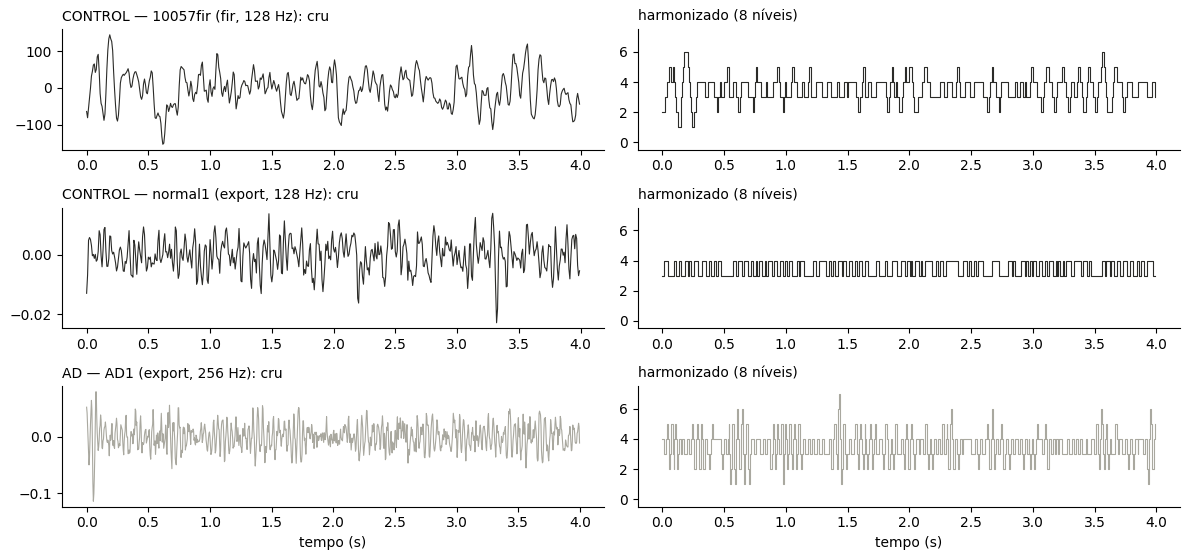

In [8]:
CANAL_EXEMPLO = 'P3'
i = CANAIS.index(CANAL_EXEMPLO)
exemplos = [pacientes.index[(pacientes.estado == 'CONTROL') & (pacientes.formato == 'fir')][0],
            *[p for p in ['normal1'] if p in pacientes.index],
            pacientes.index[pacientes.estado == 'AD'][0]]
ncol = 2 if HARMONIZAR else 1
fig, eixos = plt.subplots(len(exemplos), ncol, figsize=(6 * ncol, 1.9 * len(exemplos)), squeeze=False)
for linha, pid in enumerate(exemplos):
    p = pacientes.loc[pid]
    t = np.arange(4 * p.fs) / p.fs
    ax = eixos[linha, 0]
    ax.plot(t, janelas_cruas[pid][:len(t), i], color=CORES[p.estado], lw=0.8)
    ax.set_title(f'{p.estado} — {pid} ({p.formato}, {p.fs} Hz): cru', loc='left', fontsize=10)
    if HARMONIZAR:
        t2 = np.arange(4 * FS_ALVO) / FS_ALVO
        ax2 = eixos[linha, 1]
        ax2.step(t2, janelas[pid][:len(t2), i], color=CORES[p.estado], lw=0.8, where='mid')
        ax2.set_ylim(-0.5, N_NIVEIS - 0.5)
        ax2.set_title(f'harmonizado ({N_NIVEIS} níveis)', loc='left', fontsize=10)
    for a in eixos[linha]:
        a.spines[['top', 'right']].set_visible(False)
for a in eixos[-1]:
    a.set_xlabel('tempo (s)')
fig.tight_layout()
mostrar(fig, 'sinais')

## 2. Passo 2 — Discretização

### 2.1 DAMICORE em cada canal: distâncias, filograma e k automático

Cada pasta de canal é a entrada de uma execução do DAMICORE (`source_kind='files'`): o NCD é calculado entre todos os pares de pacientes,
a árvore é montada por Neighbor Joining e o FastGreedy escolhe o número de grupos pela modularidade (`num_clusters=None`).
Esse número é o **k automático** de cada canal.

Esta é a parte cara do notebook (cerca de 12 mil pares por canal). Uma execução já concluída com os mesmos objetos é reaproveitada,
então só a primeira vez demora. Escolher os K dos cortes (células seguintes) não refaz este cálculo.

In [9]:
from damicore import run, ExecutionConfig, OutputDirectoryConflictError, DamicoreError

DIR_DAMICORE_CANAIS = SAIDA_MODO / 'damicore_canais'

def damicore_canal(canal):
    # NCD + árvore NJ + grupos automáticos de um canal; devolve a pasta com os artefatos
    destino = DIR_DAMICORE_CANAIS / canal
    args = dict(source_kind='files', num_clusters=None, output_dir=destino, progress=False,
                execution=ExecutionConfig(workers='auto'))
    for tentativa in range(3):
        try:
            r = run(DIR_OBJETOS / canal, **args)
            break
        except OutputDirectoryConflictError:      # objetos mudaram desde a última execução: refaz
            shutil.rmtree(destino)
        except DamicoreError as e:                # Windows: arquivo temporário bloqueado; retoma do checkpoint
            if 'PermissionError' not in str(e) or tentativa == 2:
                raise
    r.close()
    return destino

linhas = []
for canal in CANAIS:
    rel = json.loads((damicore_canal(canal) / 'report.json').read_text(encoding='utf-8'))
    linhas.append(dict(canal=canal, objetos=rel['object_count'], pares=rel['pair_count'],
                       k_automatico=rel['cluster_count'], modularidade=round(rel['modularity'], 3),
                       tempo_s=round(rel['timings_seconds']['total'], 1)))
    print(f"{canal:>3}: k automático = {rel['cluster_count']}  ({rel['timings_seconds']['total']:.0f} s)")
execucoes_canais = pd.DataFrame(linhas).set_index('canal')
K_AUTO = execucoes_canais.k_automatico
execucoes_canais

Fp1: k automático = 16  (38 s)
Fp2: k automático = 17  (42 s)
 F7: k automático = 17  (44 s)
 F3: k automático = 16  (43 s)
 Fz: k automático = 15  (46 s)
 F4: k automático = 19  (45 s)
 F8: k automático = 18  (46 s)
 T3: k automático = 19  (40 s)
 C3: k automático = 16  (46 s)
 Cz: k automático = 18  (47 s)
 C4: k automático = 16  (42 s)
 T4: k automático = 17  (46 s)
 T5: k automático = 18  (44 s)
 P3: k automático = 18  (40 s)
 Pz: k automático = 19  (38 s)
 P4: k automático = 16  (47 s)
 T6: k automático = 17  (45 s)
 O1: k automático = 21  (46 s)
 O2: k automático = 18  (43 s)


,objetos,pares,k_automatico,modularidade,tempo_s
canal,,,,,
Fp1,157,12246,16,0.870,38.4
Fp2,157,12246,17,0.860,42.1
F7,157,12246,17,0.873,43.5
F3,157,12246,16,0.862,42.9
Fz,157,12246,15,0.854,46.2
F4,157,12246,19,0.862,45.1
F8,157,12246,18,0.870,46.3
T3,157,12246,19,0.859,40.4
C3,157,12246,16,0.865,46.1


### 2.2 Os cortes de cada árvore

O FastGreedy divide a árvore de um canal em K grupos **cortando K−1 ramos**: K=2 corta um ramo, K=3 corta dois, e assim por diante.
Os cortes são **aninhados**: o corte de K=3 mantém o ramo cortado em K=2 e acrescenta mais um. Por isso cada ramo cortado recebe um número,
a ordem em que o FastGreedy o corta:

- corte 1 → a árvore vira 2 grupos (K=2);
- corte 2 → 3 grupos (K=3);
- corte *n* → *n*+1 grupos.

Escolher o K de um canal é escolher até qual corte aplicar. Esta célula calcula todos os cortes de cada árvore, de K=2 até
o menor valor entre `K_MAX_PAINEL` e o k automático do canal (acima disso, as tabelas de probabilidade ficariam esparsas demais para 57 pacientes AD).
O cálculo usa o mesmo FastGreedy do DAMICORE e não refaz o NCD.

O mapa abaixo mostra, para cada canal e cada K, o NMI entre os grupos do corte e o estado (0 = os grupos não têm relação com o diagnóstico).
Ele ajuda a escolher, mas o NMI sozinho não decide: grupos pequenos demais deixam o modelo frágil.

K máximo no painel por canal: {'Fp1': 10, 'Fp2': 10, 'F7': 10, 'F3': 10, 'Fz': 10, 'F4': 10, 'F8': 10, 'T3': 10, 'C3': 10, 'Cz': 10, 'C4': 10, 'T4': 10, 'T5': 10, 'P3': 10, 'Pz': 10, 'P4': 10, 'T6': 10, 'O1': 10, 'O2': 10}


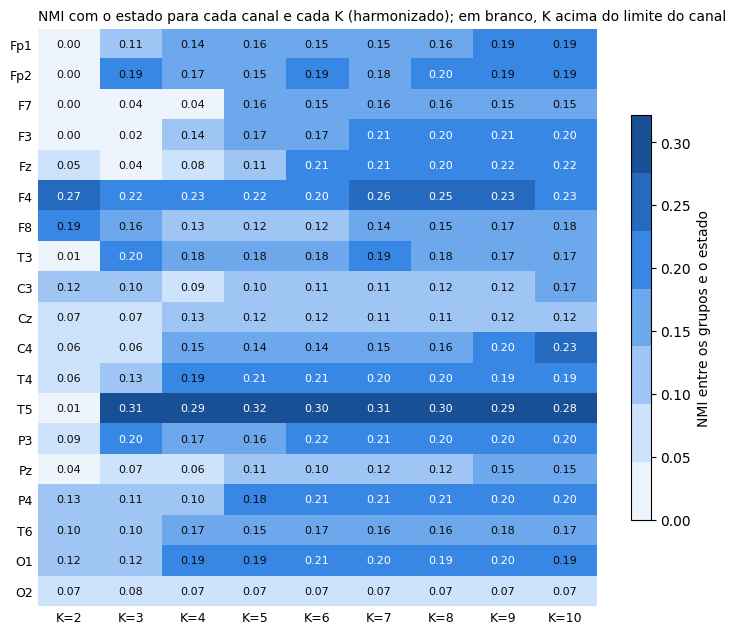

In [10]:
from damicore_clusterizer import cluster_tree, ClusterConfig
from damicore_clusterizer.tree_graph import load_tree_graph
from damicore_clusterizer.fastgreedy import fastgreedy_membership
from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score
import hashlib, sys
sys.setrecursionlimit(10000)

K_MAX_PAINEL = 10      # maior K oferecido no painel
K_PADRAO = 2           # K de um canal que ainda não foi escolhido no painel

def preparar_arvore(canal):
    # Layout do filograma e, para cada K, os grupos de cada nó e os ramos cortados
    caminho = DIR_DAMICORE_CANAIS / canal / 'tree.json'
    arv = json.loads(caminho.read_text(encoding='utf-8'))
    src = load_tree_graph(caminho.resolve())
    paciente = {oid: rot.removesuffix('.bin') for oid, rot in src.labels.items()}
    filhos, comp, pai = {}, {}, {}
    for e in arv['edges']:
        filhos.setdefault(e['source'], []).append(e['target'])
        comp[e['target']] = e['length']
        pai[e['target']] = e['source']
    x, y, folhas = {}, {}, []

    def posicionar(no, x0):
        x[no] = x0
        if no not in filhos:
            y[no] = len(folhas)
            folhas.append(no)
            return
        for f in filhos[no]:
            posicionar(f, x0 + comp[f])
        y[no] = np.mean([y[f] for f in filhos[no]])

    posicionar(arv['root_id'], 0.0)
    # Escala 'topologia': cada nível da árvore tem a mesma largura e as folhas ficam alinhadas à direita
    prof = {}
    def profundidade(no, d):
        prof[no] = d
        for f in filhos.get(no, []):
            profundidade(f, d + 1)
    profundidade(arv['root_id'], 0)
    dmax = max(prof.values())
    x_topo = {no: (prof[no] if no in filhos else dmax) for no in prof}
    kmax = int(min(K_MAX_PAINEL, K_AUTO[canal]))
    cortes, grupo_no, particao, modularidade = {}, {}, {}, {}
    for k in range(2, kmax + 1):
        memb, _, mod = fastgreedy_membership(src.graph, k)
        com = {src.vertex_names[v]: c for v, c in enumerate(memb)}
        for no in filhos:                          # a raiz do NJ não é um vértice do grafo sem raiz (os seus dois filhos se ligam
            if no not in com:                      # direto): ela herda o grupo do primeiro filho
                com[no] = com[filhos[no][0]] if filhos[no][0] in com else com[filhos[no][1]]
        por_com = {}
        for oid in src.object_ids:
            por_com.setdefault(com[oid], []).append(oid)
        # mesma numeração do cluster_tree: grupos ordenados pelos identificadores dos objetos
        ordenados = sorted(tuple(sorted(g)) for g in por_com.values())
        numero = {com[g[0]]: i for i, g in enumerate(ordenados)}
        grupo_no[k] = {no: numero.get(c, -1) for no, c in com.items()}
        particao[k] = pd.Series({paciente[oid]: grupo_no[k][oid] for oid in src.object_ids})
        modularidade[k] = mod
        for filho, p in pai.items():
            if com[filho] != com[p] and (p, filho) not in cortes:
                cortes[p, filho] = k            # ramo cortado pela primeira vez neste K
    return dict(canal=canal, x={'comprimento': x, 'topologia': x_topo}, y=y, folhas=folhas, filhos=filhos, paciente=paciente, kmax=kmax,
                cortes=cortes, grupo_no=grupo_no, particao=particao, modularidade=modularidade)

ARVORES = {canal: preparar_arvore(canal) for canal in CANAIS}

nmi_k = pd.DataFrame({k: {c: normalized_mutual_info_score(pacientes.estado, A['particao'][k].reindex(pacientes.index))
                          for c, A in ARVORES.items() if k <= A['kmax']}
                      for k in range(2, K_MAX_PAINEL + 1)}).reindex(CANAIS)
nmi_k.index.name = 'canal'
nmi_k.columns.name = 'K'
print('K máximo no painel por canal:', {c: A['kmax'] for c, A in ARVORES.items()})

fig, ax = plt.subplots(figsize=(9, 7.5))
vmax = max(0.3, np.nanmax(nmi_k.values))
cmap_nmi = ListedColormap(['#eef4fc', '#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95'])
cmap_nmi.set_bad('#ffffff')
im = ax.imshow(np.ma.masked_invalid(nmi_k.values), cmap=cmap_nmi, vmin=0, vmax=vmax, aspect='auto')
for i in range(nmi_k.shape[0]):
    for j in range(nmi_k.shape[1]):
        v = nmi_k.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8, color='#ffffff' if v > 0.6 * vmax else '#0b0b0b')
ax.set_xticks(range(nmi_k.shape[1]), [f'K={k}' for k in nmi_k.columns], fontsize=9)
ax.set_yticks(range(len(CANAIS)), CANAIS, fontsize=9)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.7, label='NMI entre os grupos e o estado')
ax.set_title(f'NMI com o estado para cada canal e cada K ({MODO}); em branco, K acima do limite do canal', loc='left', fontsize=10)
mostrar(fig, 'mapa_k')

### 2.3 Desenho do corte

Cada árvore é desenhada a partir da raiz gravada pelo DAMICORE, em uma de duas escalas:

- **topologia** (padrão): cada nível da árvore tem a mesma largura e as folhas ficam alinhadas à direita. É a escala em que os cortes ficam visíveis,
  porque os ramos internos, onde o FastGreedy corta, ficam do mesmo tamanho dos outros;
- **comprimento**: o comprimento horizontal de cada ramo é o seu comprimento (NCD). Os ramos até as folhas são longos (NCD perto de 0,45)
  e os internos, curtos, então a estrutura interna fica comprimida perto da raiz.

Elementos do desenho:

- **Ramos coloridos:** cada cor é um grupo do corte. Ramos cinza pertencem a uma parte da árvore que não contém nenhum paciente.
- **Ramos cortados:** tracejado vermelho, com um círculo vermelho e o número do corte.
- **Próximos cortes:** números cinza nos ramos que seriam cortados se o K aumentasse.
- **Duas faixas à direita das folhas:** a primeira mostra o estado do paciente (que o DAMICORE não usou; cinza-escuro = CONTROL,
  cinza-claro = AD), a segunda o grupo do corte.

In [11]:
from matplotlib.patches import Rectangle

COR_CORTE = '#d03b3b'

def desenhar_corte(ax, A, k, compacto=False, escala='topologia'):
    x, y, grupo = A['x'][escala], A['y'], A['grupo_no'][k]
    cor = lambda no: cor_grupo(grupo[no]) if grupo[no] >= 0 else '#b9b8b0'
    lw = 0.7 if compacto else 1.3
    for p, fs in A['filhos'].items():
        ax.plot([x[p], x[p]], [min(y[f] for f in fs), max(y[f] for f in fs)], color=cor(p), lw=lw, solid_capstyle='butt')
        for f in fs:
            kc = A['cortes'].get((p, f))
            xm = (x[p] + x[f]) / 2
            if kc is not None and kc <= k:
                ax.plot([x[p], x[f]], [y[f], y[f]], color=COR_CORTE, lw=lw * 1.4, ls=(0, (2, 1.2)))
                ax.scatter(xm, y[f], s=70 if compacto else 260, color=COR_CORTE, edgecolor='white', linewidth=1.2, zorder=5)
                ax.text(xm, y[f], str(kc - 1), ha='center', va='center', color='white', fontsize=6 if compacto else 9,
                        fontweight='bold', zorder=6)
            else:
                ax.plot([x[p], x[f]], [y[f], y[f]], color=cor(f), lw=lw)
                if kc is not None and not compacto:
                    ax.text(xm, y[f] - 0.6, str(kc - 1), ha='center', va='bottom', color='#9a998f', fontsize=7)
    xmax = max(x.values())
    for f in A['folhas']:
        p = A['paciente'][f]
        ax.add_patch(Rectangle((xmax * 1.03, y[f] - 0.5), xmax * 0.04, 1, color=CORES[pacientes.loc[p, 'estado']], lw=0))
        ax.add_patch(Rectangle((xmax * 1.08, y[f] - 0.5), xmax * 0.04, 1, color=cor(f), lw=0))
    if not compacto:
        ax.text(xmax * 1.05, -1.5, 'estado', rotation=90, ha='center', va='bottom', fontsize=8, color='#5f5e57')
        ax.text(xmax * 1.10, -1.5, 'grupo', rotation=90, ha='center', va='bottom', fontsize=8, color='#5f5e57')
        ax.set_xlabel('comprimento acumulado dos ramos (NCD)' if escala == 'comprimento' else 'nível na árvore, a partir da raiz (topologia)')
    ax.set_xlim(-xmax * 0.02, xmax * 1.14)
    ax.set_ylim(len(A['folhas']) - 0.5, -0.5 - (0 if compacto else 8))
    ax.set_yticks([])
    if compacto:
        ax.set_xticks([])
    ax.spines[['top', 'right', 'left']].set_visible(False)

def composicao(A, k):
    # Pacientes de cada estado em cada grupo do corte
    part = A['particao'][k].reindex(pacientes.index)
    return pd.crosstab(part.rename('grupo'), pacientes.estado).reindex(columns=ESTADOS, fill_value=0)

def legenda_corte(ax, k):
    alcas = ([Line2D([], [], marker='s', ls='', markersize=9, color=CORES[e], label=e) for e in ESTADOS] +
             [Line2D([], [], marker='s', ls='', markersize=9, color=cor_grupo(g), label=f'grupo {g}') for g in range(k)] +
             [Line2D([], [], marker='o', ls='--', color=COR_CORTE, markersize=9, label='ramo cortado (nº do corte)')])
    ax.legend(handles=alcas, loc='lower left', frameon=False, fontsize=8, ncol=2)

### 2.4 Painel: escolha do K de cada canal

**Como usar:**
1. Escolha o canal na lista e mova o K (a escala do desenho pode ser trocada nos botões): a árvore é redesenhada com o corte daquele K, e a tabela abaixo dela mostra quantos pacientes
   de cada estado caíram em cada grupo.
2. O K de cada canal fica guardado enquanto você passa pelos outros canais. A linha "K escolhidos" mostra os 19 valores.
3. Depois de ver todos, clique em **Aplicar os K selecionados**: os valores são gravados em `saida/<modo>/k_por_canal.json`.
4. Use **Executar abaixo** a partir da célula seguinte (2.5): o restante do pipeline roda sozinho até o relatório.

Se o painel não aparecer (por exemplo, numa execução automática do notebook inteiro), o pipeline usa o `k_por_canal.json` já gravado
ou, se ele não existir, `K_PADRAO` em todos os canais.

Escolher o K olhando a faixa do estado é ajustar a discretização pelo diagnóstico. Sem validação cruzada, isso deixa a classificação
dos pacientes reais mais otimista; o relatório registra a escolha.

In [ ]:
import ipywidgets as W

ARQ_K = SAIDA_MODO / 'k_por_canal.json'

def ler_k_salvo():
    if ARQ_K.is_file():
        salvo = json.loads(ARQ_K.read_text(encoding='utf-8'))
        return {c: int(min(max(2, salvo.get(c, K_PADRAO)), ARVORES[c]['kmax'])) for c in CANAIS}, True
    return {c: int(min(K_PADRAO, ARVORES[c]['kmax'])) for c in CANAIS}, False

K_ESCOLHA, _ = ler_k_salvo()

sel_canal = W.Dropdown(options=CANAIS, value=CANAIS[0], description='Canal', layout=W.Layout(width='180px'))
sel_k = W.IntSlider(min=2, max=ARVORES[CANAIS[0]]['kmax'], value=K_ESCOLHA[CANAIS[0]], description='K',
                    continuous_update=False, layout=W.Layout(width='420px'))
sel_escala = W.ToggleButtons(options=[('topologia', 'topologia'), ('comprimento dos ramos', 'comprimento')], value='topologia',
                             description='Escala', style={'button_width': '150px'})
area_fig, area_info, area_lista, area_msg = W.Output(), W.HTML(), W.HTML(), W.HTML()
botao = W.Button(description='Aplicar os K selecionados', button_style='success', icon='check', layout=W.Layout(width='260px'))

def lista_html():
    itens = ' · '.join(f"<b>{c}</b> {K_ESCOLHA[c]}" if K_ESCOLHA[c] != K_PADRAO else f'{c} {K_ESCOLHA[c]}' for c in CANAIS)
    return f'<p style="margin:4px 0"><b>K escolhidos:</b> {itens}</p>'

def redesenhar(*_):
    canal, k = sel_canal.value, sel_k.value
    A = ARVORES[canal]
    K_ESCOLHA[canal] = k
    comp_k = composicao(A, k)
    with area_fig:
        area_fig.clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(10, 11))
        desenhar_corte(ax, A, k, escala=sel_escala.value)
        legenda_corte(ax, k)
        ax.set_title(f'{canal} — K = {k}: {k - 1} ramo(s) cortado(s) · NMI com o estado {nmi_k.loc[canal, k]:.2f} '
                     f'· k automático {K_AUTO[canal]}', loc='left', fontsize=11)
        plt.show()
    area_info.value = ('<p style="margin:4px 0">Pacientes por grupo: ' +
                       ' · '.join(f'<span style="color:{cor_grupo(g)}">■</span> grupo {g}: {r.CONTROL} CONTROL | {r.AD} AD'
                                  for g, r in comp_k.iterrows()) + '</p>')
    area_lista.value = lista_html()

def trocar_canal(mudanca):
    A = ARVORES[mudanca.new]
    sel_k.unobserve(redesenhar, 'value')
    sel_k.max = A['kmax']
    sel_k.value = K_ESCOLHA[mudanca.new]
    sel_k.observe(redesenhar, 'value')
    redesenhar()

def aplicar(_):
    ARQ_K.write_text(json.dumps(K_ESCOLHA, indent=2), encoding='utf-8')
    area_msg.value = (f'<p style="color:#1a7f4b"><b>Gravado em {ARQ_K}.</b> Agora use "Executar abaixo" a partir da célula seguinte (2.5).</p>')

sel_canal.observe(trocar_canal, 'value')
sel_k.observe(redesenhar, 'value')
sel_escala.observe(redesenhar, 'value')
botao.on_click(aplicar)
display(W.VBox([W.HBox([sel_canal, sel_k]), sel_escala, area_fig, area_info, area_lista, botao, area_msg]))
redesenhar()

### 2.5 Aplicação dos K e tabela de discretização

Lê os K gravados pelo painel (ou usa `K_PADRAO`) e corta cada árvore com o `cluster_tree` do DAMICORE, que grava os grupos de cada canal.
O grupo de cada paciente em cada canal é a sua discretização: um valor de 0 a K−1, onde o K pode ser diferente em cada canal.

Cada configuração grava em `saida/<modo>/<configuração>/`: `K2` quando todos os canais têm K=2, ou `Kcanal_<código>` quando os K variam.

In [27]:
K_POR_CANAL, K_DO_PAINEL = ler_k_salvo()
valores = sorted(set(K_POR_CANAL.values()))
if len(valores) == 1:
    CONFIG = f'K{valores[0]}'
    K_TXT = f'K = {valores[0]} em todos os canais'
else:
    CONFIG = 'Kcanal_' + hashlib.md5(','.join(str(K_POR_CANAL[c]) for c in CANAIS).encode()).hexdigest()[:6]
    K_TXT = 'K por canal: ' + ', '.join(f'{c}={K_POR_CANAL[c]}' for c in CANAIS)
K_LISTA = ','.join(str(K_POR_CANAL[c]) for c in CANAIS)
K_MAX_SEL = max(K_POR_CANAL.values())
SAIDA_K = SAIDA_MODO / CONFIG
SAIDA_K.mkdir(exist_ok=True)
(SAIDA_K / 'k_por_canal.json').write_text(json.dumps(K_POR_CANAL, indent=2), encoding='utf-8')
print(f"{K_TXT}  ({'gravado pelo painel' if K_DO_PAINEL else 'K_PADRAO, sem escolha no painel'})")
print(f'Configuração: {CONFIG} -> {SAIDA_K}')

def cortar_arvore(canal):
    # Corta o filograma do canal no K escolhido e devolve o grupo de cada paciente
    k = K_POR_CANAL[canal]
    destino = SAIDA_K / 'corte_arvores' / canal
    if destino.exists():
        shutil.rmtree(destino)
    res = cluster_tree(DIR_DAMICORE_CANAIS / canal / 'tree.json', destino, config=ClusterConfig(num_clusters=k))
    m = pd.read_csv(res.membership_path)
    grupos = pd.Series(m.cluster.values, index=m.label.str.removesuffix('.bin').values)
    desenho = ARVORES[canal]['particao'][k]
    assert (grupos.reindex(desenho.index) == desenho).all(), f'{canal}: o corte do cluster_tree difere do desenho'
    return grupos

tabela = pd.DataFrame({canal: cortar_arvore(canal) for canal in CANAIS}).reindex(pacientes.index).astype(int)
tabela.index.name = 'paciente'
tabela.insert(0, 'estado', pacientes.estado)
tabela.to_csv(SAIDA_K / 'tabela_discretizacao.csv')

def distribuicao(serie, k):
    return ' / '.join(str(int((serie == v).sum())) for v in range(k))

corte = pd.DataFrame({
    'k_automatico': K_AUTO,
    'K': pd.Series(K_POR_CANAL),
    'grupos_no_corte': tabela[CANAIS].nunique(),
    'CONTROL': {c: distribuicao(tabela.loc[tabela.estado == 'CONTROL', c], K_POR_CANAL[c]) for c in CANAIS},
    'AD': {c: distribuicao(tabela.loc[tabela.estado == 'AD', c], K_POR_CANAL[c]) for c in CANAIS},
    'NMI_estado': {c: round(normalized_mutual_info_score(tabela.estado, tabela[c]), 3) for c in CANAIS},
    'NMI_formato': {c: round(normalized_mutual_info_score(pacientes.formato, tabela[c]), 3) for c in CANAIS},
})

# Os dois controles `export` (normal1, normal2) estão no formato dos AD. Num canal, um deles "segue o formato"
# quando cai no grupo da maioria dos AD e esse grupo é diferente do grupo da maioria dos controles `fir`.
NORMAIS_ID = [p for p in ['normal1', 'normal2'] if p in tabela.index]
def normais_seguem_formato(c):
    moda_ad = tabela.loc[tabela.estado == 'AD', c].mode()[0]
    moda_fir = tabela.loc[pacientes.formato == 'fir', c].mode()[0]
    return int(sum(moda_ad != moda_fir and tabela.loc[p, c] == moda_ad for p in NORMAIS_ID))
corte['normais_seguem_formato'] = [normais_seguem_formato(c) for c in CANAIS]
corte['aviso'] = np.where(corte.grupos_no_corte < corte.K, 'menos grupos que K', '')
corte.index.name = 'canal'
AVISOS_CORTE = corte.loc[corte.aviso != '', 'aviso'].to_dict()
print(f'Tabela de discretização: {tabela.shape[0]} pacientes x {len(CANAIS)} canais -> {SAIDA_K / "tabela_discretizacao.csv"}')
print('Colunas CONTROL e AD: número de pacientes em cada grupo (0 / 1 / ...).')
corte

K por canal: Fp1=3, Fp2=2, F7=4, F3=3, Fz=2, F4=2, F8=4, T3=4, C3=4, Cz=3, C4=4, T4=3, T5=5, P3=5, Pz=4, P4=3, T6=3, O1=3, O2=4  (gravado pelo painel)
Configuração: Kcanal_10c752 -> c:\DAMICORE\DAMICORE_v3\saida\harmonizado\Kcanal_10c752
Tabela de discretização: 157 pacientes x 19 canais -> c:\DAMICORE\DAMICORE_v3\saida\harmonizado\Kcanal_10c752\tabela_discretizacao.csv
Colunas CONTROL e AD: número de pacientes em cada grupo (0 / 1 / ...).


,k_automatico,K,grupos_no_corte,CONTROL,AD,NMI_estado,NMI_formato,normais_seguem_formato,aviso
canal,,,,,,,,,
Fp1,16,3,3,43 / 27 / 30,26 / 0 / 31,0.112,0.117,1,
Fp2,17,2,2,39 / 61,27 / 30,0.005,0.009,0,
F7,17,4,4,19 / 28 / 31 / 22,12 / 4 / 26 / 15,0.037,0.040,0,
F3,16,3,3,43 / 39 / 18,15 / 25 / 17,0.020,0.028,0,
Fz,15,2,2,73 / 27,27 / 30,0.050,0.063,2,
F4,19,2,2,48 / 52,0 / 57,0.275,0.287,0,
F8,18,4,4,41 / 10 / 32 / 17,1 / 17 / 25 / 14,0.127,0.131,1,
T3,19,4,4,33 / 5 / 52 / 10,10 / 31 / 9 / 7,0.182,0.175,0,
C3,16,4,4,36 / 28 / 22 / 14,7 / 8 / 13 / 29,0.090,0.084,0,


**Como ler a tabela (viés de aparelho):**

- `NMI_estado` e `NMI_formato` medem o quanto o grupo de um canal coincide com o diagnóstico e com o formato do arquivo
  (0 = nenhuma relação, 1 = o canal separa sozinho). Como quase todos os controles são `fir` e todos os AD são `export`,
  os dois números ficam parecidos e, sozinhos, não dizem qual dos dois efeitos o DAMICORE encontrou.
- `normais_seguem_formato` desempata: conta quantos dos dois controles `export` (`normal1`, `normal2`) caem no grupo dos AD,
  e não no dos controles. Se isso acontece em quase todos os canais, a discretização está seguindo o aparelho.

A figura mostra a tabela inteira: cada linha é um paciente, cada coluna um canal, e a cor é o grupo.
Os controles estão em cima (primeiro os `fir`, depois os dois `export`, logo acima da linha branca) e os AD embaixo.
Se as duas linhas dos `normal` tiverem as cores do bloco AD, a discretização está seguindo o aparelho.

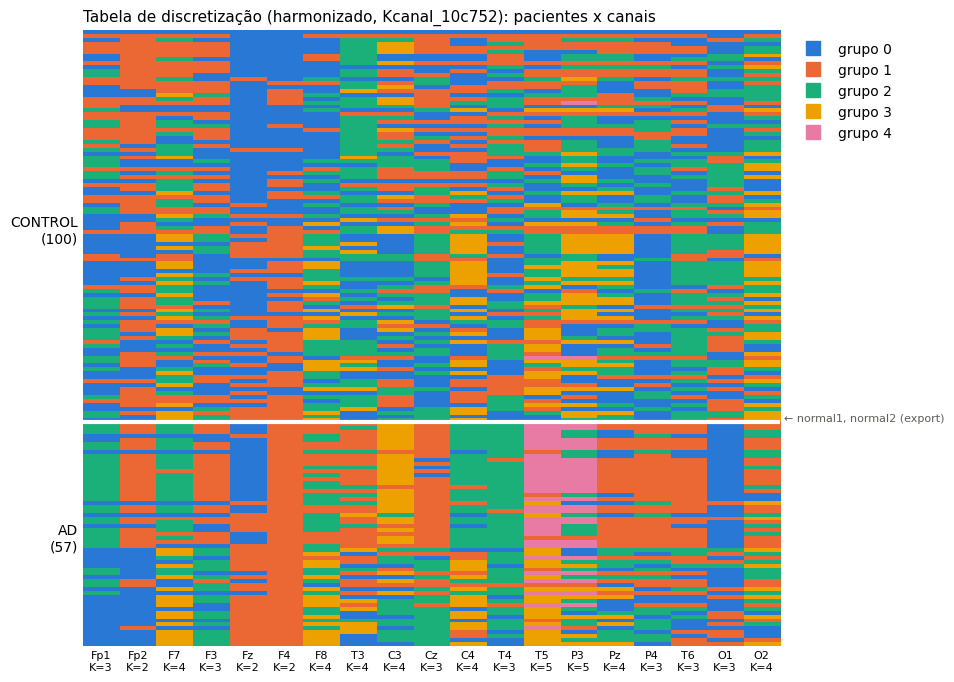

In [28]:
cmap_k = ListedColormap([cor_grupo(v) for v in range(K_MAX_SEL)])
# CONTROL fir, depois os CONTROL export (normal1, normal2, logo acima da linha) e por fim os AD
ordem = tabela.loc[sorted(tabela.index, key=lambda p: (ESTADOS.index(tabela.loc[p, 'estado']), pacientes.loc[p, 'formato'] == 'export'))]
fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(ordem[CANAIS].values, aspect='auto', cmap=cmap_k, vmin=-0.5, vmax=K_MAX_SEL - 0.5, interpolation='nearest')
ax.set_xticks(range(len(CANAIS)), [f'{c}\nK={K_POR_CANAL[c]}' for c in CANAIS], fontsize=8)
n_c = N_ESTADO['CONTROL']
ax.axhline(n_c - 0.5, color='white', lw=3)
ax.set_yticks([n_c / 2, n_c + N_ESTADO['AD'] / 2], [f"CONTROL\n({n_c})", f"AD\n({N_ESTADO['AD']})"], fontsize=10)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
alcas = [Line2D([], [], marker='s', ls='', markersize=10, color=cor_grupo(v), label=f'grupo {v}') for v in range(K_MAX_SEL)]
ax.legend(handles=alcas, loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False)
ax.set_title(f'Tabela de discretização ({MODO}, {CONFIG}): pacientes x canais', loc='left', fontsize=11)
ax.text(len(CANAIS) - 0.4, n_c - 1.5, '← normal1, normal2 (export)', fontsize=8, va='center', ha='left', color='#5f5e57')
mostrar(fig, 'discretizacao')

### 2.6 As 19 árvores com o corte aplicado

Visão de conjunto da escolha: cada painel é a árvore de um canal com o seu K, os ramos cortados em vermelho
e as faixas de estado e de grupo à direita. Esta figura vai para o relatório.

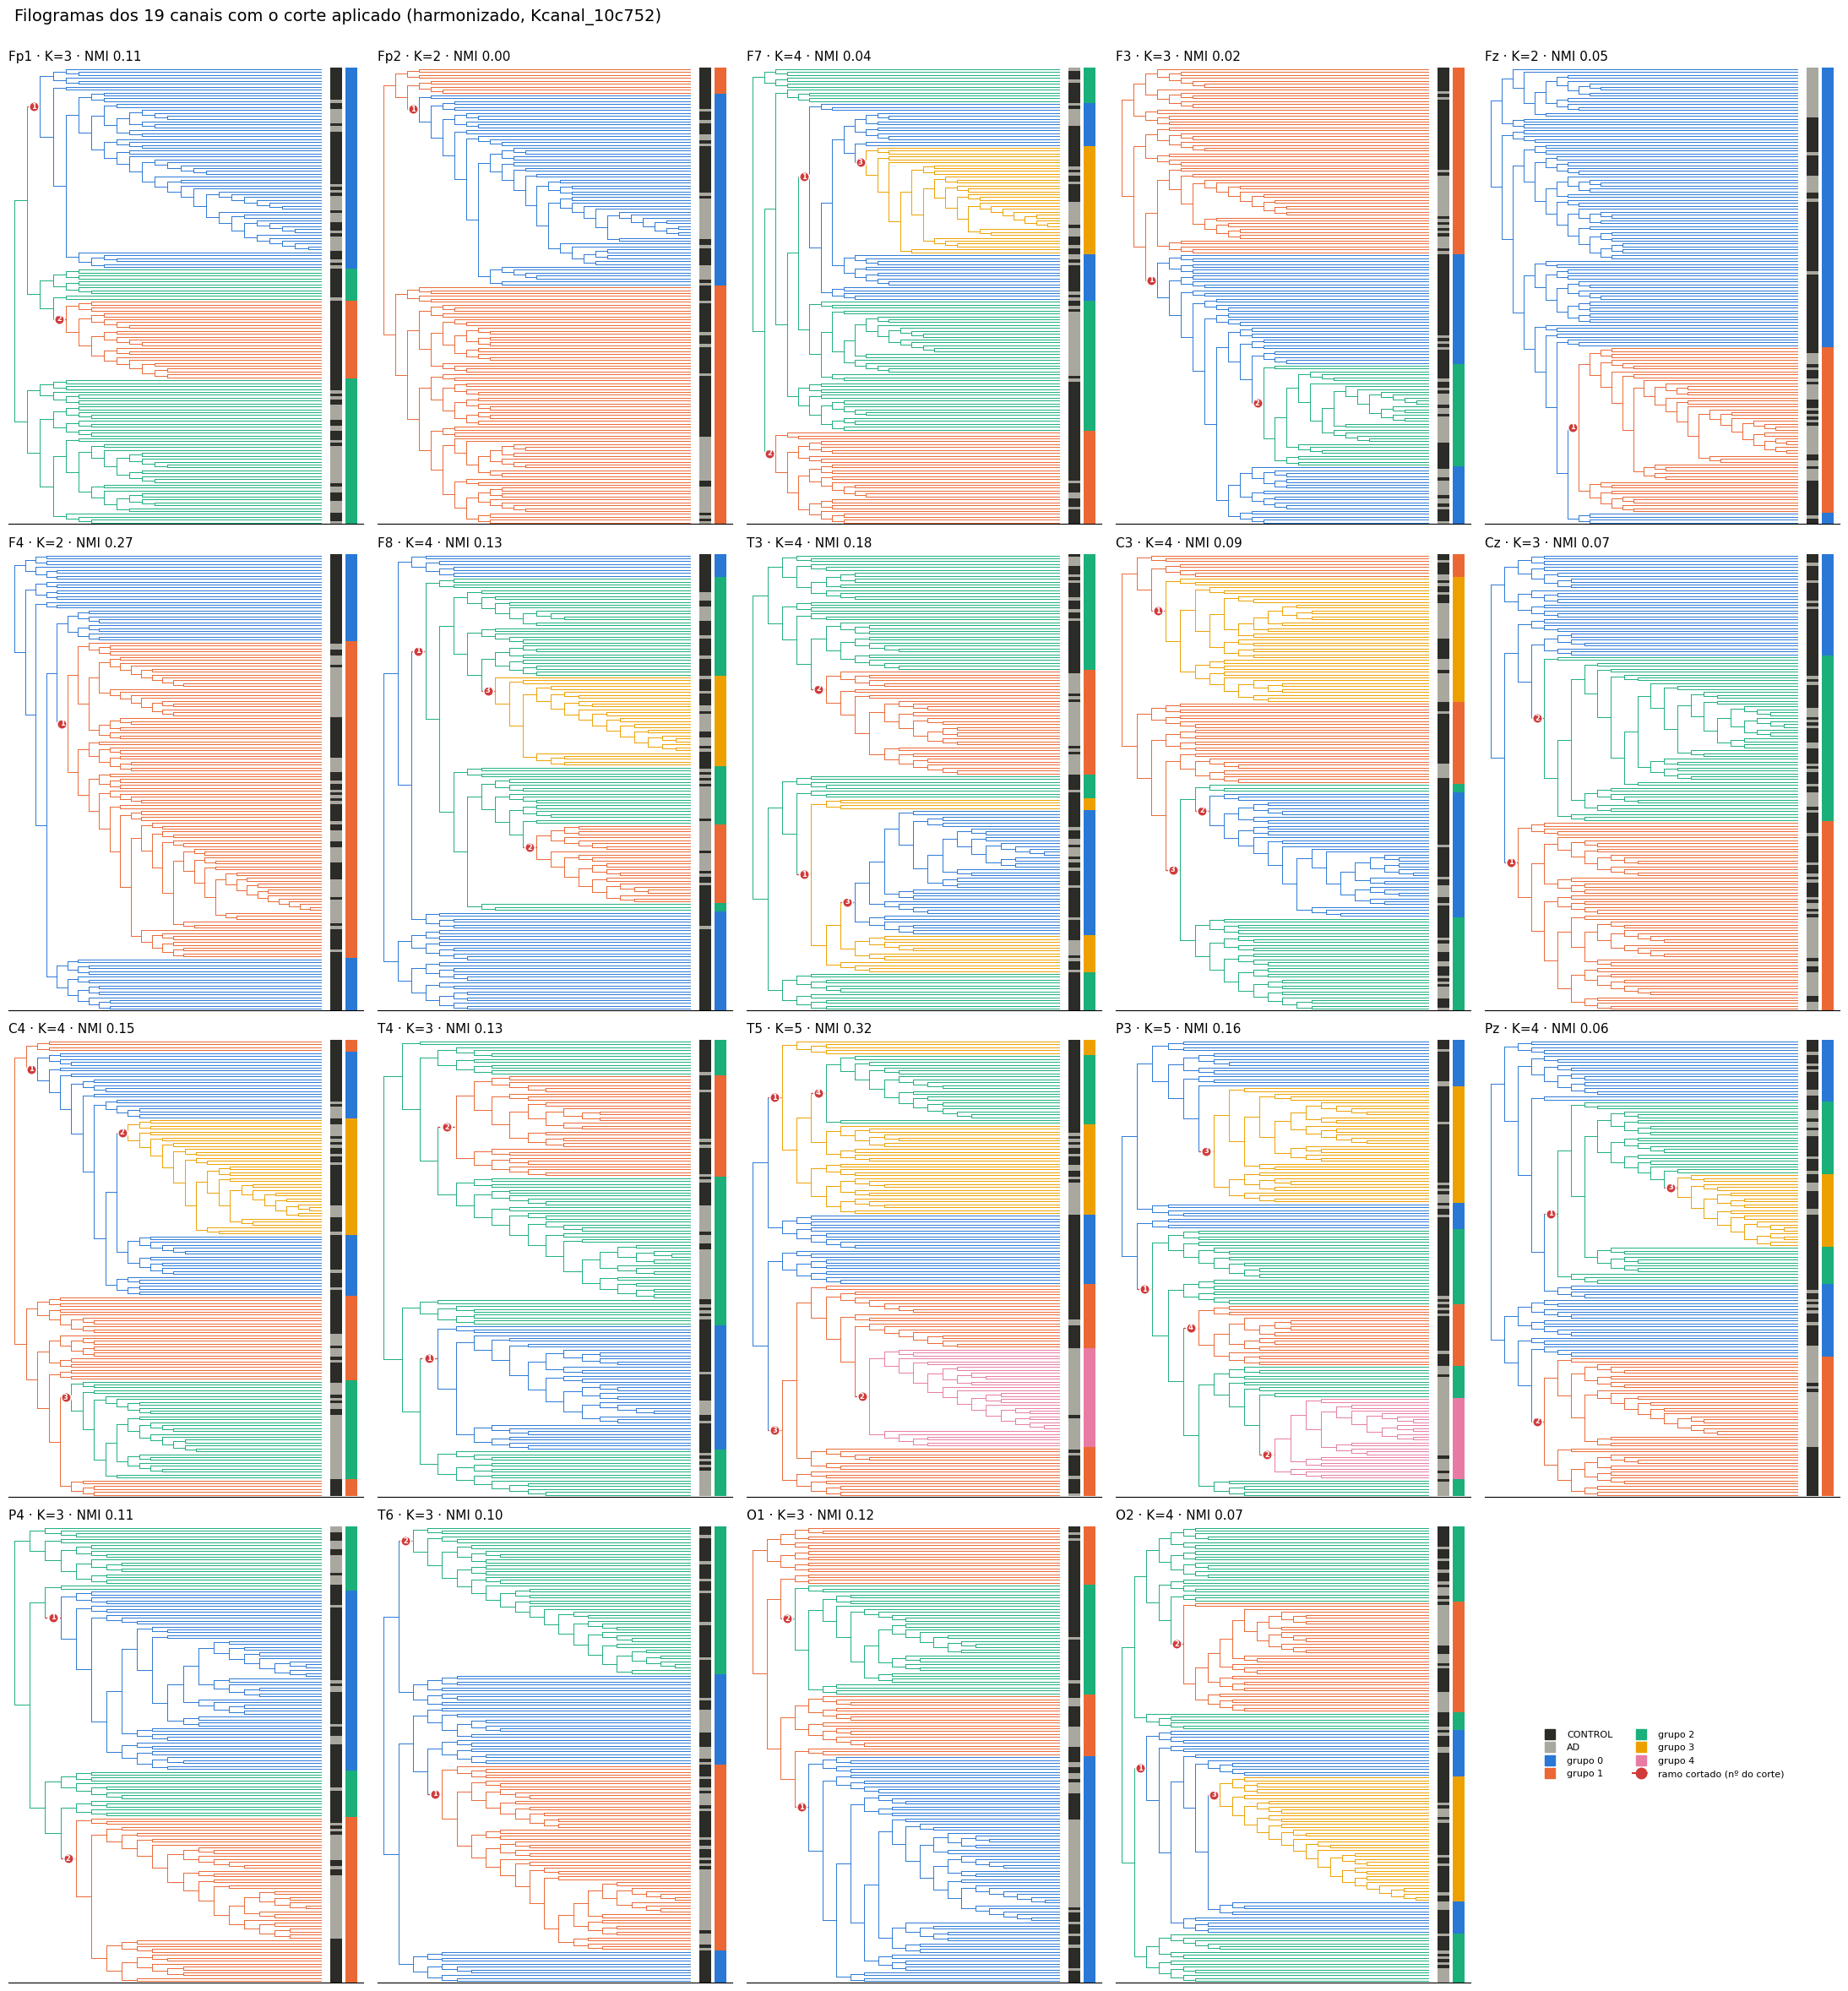

In [29]:
fig, eixos = plt.subplots(4, 5, figsize=(22, 24))
for ax, canal in zip(eixos.flat, CANAIS):
    k = K_POR_CANAL[canal]
    desenhar_corte(ax, ARVORES[canal], k, compacto=True)
    ax.set_title(f'{canal} · K={k} · NMI {nmi_k.loc[canal, k]:.2f}', loc='left', fontsize=11)
ax_leg = eixos.flat[len(CANAIS)]
ax_leg.axis('off')
legenda_corte(ax_leg, K_MAX_SEL)
ax_leg.get_legend().set_loc('center')
fig.suptitle(f'Filogramas dos 19 canais com o corte aplicado ({MODO}, {CONFIG})', x=0.01, ha='left', fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.98))
mostrar(fig, 'arvores')

## 3. Passo 3 — Grupos de canais (estrutura do modelo)

Agora o diagnóstico entra. A tabela de discretização é separada por estado, e o DAMICORE roda uma vez para cada estado,
com **cada canal (coluna) como objeto**: o objeto de um canal é a sequência dos grupos dos pacientes daquele estado naquele canal.
O NCD compara essas sequências, e o FastGreedy reúne os canais que discretizaram os pacientes de modo parecido.
O número de grupos de canais é automático (`num_clusters=None`), como no v2.

No EDA, este é o aprendizado da estrutura: canais do mesmo grupo são tratados como dependentes entre si; grupos diferentes, como independentes.

**Canais idênticos:** se dois canais têm exatamente a mesma sequência num estado (acontece, por exemplo, quando todos os pacientes
caem no mesmo grupo), eles seriam objetos idênticos, com NCD = 0, e a árvore NJ teria um ramo de comprimento zero, que o DAMICORE não aceita.
Por isso, só um representante de cada sequência entra no DAMICORE, e os canais repetidos voltam depois para o grupo do seu representante.

In [31]:
DIR_GRUPOS = SAIDA_K / 'grupos_canais'

def damicore_tabela(estado):
    dados = tabela.loc[tabela.estado == estado, CANAIS]
    representante, vistos = {}, {}
    for c in CANAIS:                                       # canais com a mesma sequência -> um representante
        representante[c] = vistos.setdefault(tuple(dados[c]), c)
    unicos = list(dict.fromkeys(representante.values()))
    repetidos = {r: [c for c in CANAIS if representante[c] == r] for r in unicos}
    repetidos = {r: cs for r, cs in repetidos.items() if len(cs) > 1}

    pasta = DIR_GRUPOS / estado
    pasta.mkdir(parents=True, exist_ok=True)
    if len(unicos) < 3:                                    # poucos objetos distintos para montar uma árvore
        return {c: unicos.index(representante[c]) for c in CANAIS}, dict(modularity=float('nan')), repetidos
    entrada = pasta / 'entrada.csv'
    dados[unicos].to_csv(entrada, index=False)             # só os canais: paciente e estado não são objetos
    destino = pasta / 'damicore'
    args = dict(source_kind='delimited', split='columns', num_clusters=None, output_dir=destino,
                keep_normalized=True, save_diagnostics=True, progress=False)
    try:
        r = run(entrada, **args)
    except (OutputDirectoryConflictError, DamicoreError) as e:   # a tabela mudou, ou sobrou uma execução incompleta: refaz
        if isinstance(e, DamicoreError) and not destino.exists():
            raise
        shutil.rmtree(destino)
        r = run(entrada, **args)
    r.close()
    relatorio = json.loads((destino / 'report.json').read_text(encoding='utf-8'))
    membros = pd.read_csv(destino / 'membership.csv').set_index('label')['cluster']
    return {c: int(membros[representante[c]]) for c in CANAIS}, relatorio, repetidos

GRUPOS, MODULARIDADE, REPETIDOS = {}, {}, {}
for estado in ESTADOS:
    membros, relatorio, REPETIDOS[estado] = damicore_tabela(estado)
    GRUPOS[estado] = {g: sorted([c for c in CANAIS if membros[c] == g], key=CANAIS.index) for g in sorted(set(membros.values()))}
    MODULARIDADE[estado] = relatorio['modularity']
    print(f'{estado}: {len(GRUPOS[estado])} grupos de canais, modularidade {relatorio["modularity"]:.3f}')
    for g, canais in GRUPOS[estado].items():
        print(f'   grupo {g}: {", ".join(canais)}')
    for r, cs in REPETIDOS[estado].items():
        print(f'   canais idênticos (entraram como um só objeto): {", ".join(cs)}')

grupo_do_canal = pd.DataFrame({e: {c: g for g, cs in GRUPOS[e].items() for c in cs} for e in ESTADOS}).reindex(CANAIS)
ARI_ESTADOS = adjusted_rand_score(grupo_do_canal.CONTROL, grupo_do_canal.AD)
print(f'\nARI entre os grupos de canais do CONTROL e do AD: {ARI_ESTADOS:.3f} (1 = mesmos canais juntos, 0 = acaso)')

CONTROL: 6 grupos de canais, modularidade 0.630
   grupo 0: Fp1, F3, T4, P4, O1
   grupo 1: Fp2, Fz, F4
   grupo 2: F7, C3, Pz
   grupo 3: F8, C4
   grupo 4: T3, Cz, T6
   grupo 5: T5, P3, O2
AD: 6 grupos de canais, modularidade 0.636
   grupo 0: Fp1, Fp2, Fz, O1
   grupo 1: F7, C3
   grupo 2: F3, T5, P4, T6
   grupo 3: F4, Cz, T4
   grupo 4: F8, P3, O2
   grupo 5: T3, C4, Pz

ARI entre os grupos de canais do CONTROL e do AD: 0.104 (1 = mesmos canais juntos, 0 = acaso)


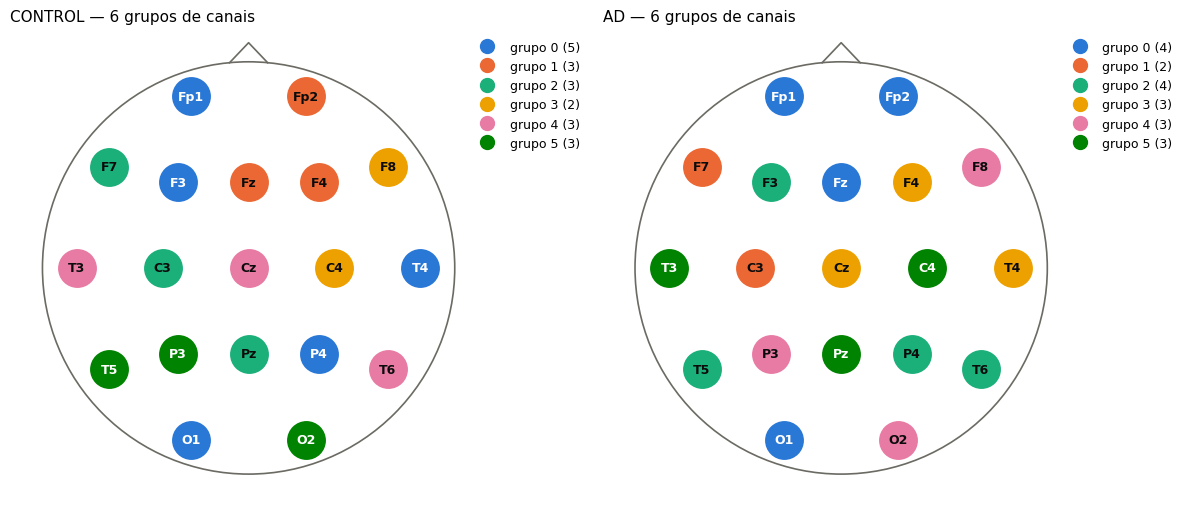

In [32]:
POSICOES = {'Fp1': (-0.3, 0.9), 'Fp2': (0.3, 0.9), 'F7': (-0.73, 0.53), 'F3': (-0.37, 0.45), 'Fz': (0, 0.45),
            'F4': (0.37, 0.45), 'F8': (0.73, 0.53), 'T3': (-0.9, 0), 'C3': (-0.45, 0), 'Cz': (0, 0), 'C4': (0.45, 0),
            'T4': (0.9, 0), 'T5': (-0.73, -0.53), 'P3': (-0.37, -0.45), 'Pz': (0, -0.45), 'P4': (0.37, -0.45),
            'T6': (0.73, -0.53), 'O1': (-0.3, -0.9), 'O2': (0.3, -0.9)}
TINTA_ESCURA = ('#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#17becf', '#bcbd22')

fig, eixos = plt.subplots(1, len(ESTADOS), figsize=(12, 6))
for ax, estado in zip(eixos, ESTADOS):
    g = grupo_do_canal[estado]
    ax.add_patch(plt.Circle((0, 0), 1.08, fill=False, color='#6b6a63', lw=1.2))
    ax.plot([-0.1, 0, 0.1], [1.075, 1.18, 1.075], color='#6b6a63', lw=1.2)          # nariz
    for canal, (px, py) in POSICOES.items():
        cor = cor_grupo(g[canal])
        ax.scatter(px, py, s=900, color=cor, edgecolor='white', linewidth=2, zorder=3)
        ax.text(px, py, canal, ha='center', va='center', fontsize=9, fontweight='bold', zorder=4,
                color='#0b0b0b' if cor in TINTA_ESCURA else '#ffffff')
    alcas = [Line2D([], [], marker='o', ls='', markersize=10, color=cor_grupo(k), label=f'grupo {k} ({(g == k).sum()})')
             for k in sorted(g.unique())]
    ax.legend(handles=alcas, loc='upper left', bbox_to_anchor=(0.95, 1), frameon=False, fontsize=9)
    ax.set_title(f'{estado} — {g.nunique()} grupos de canais', loc='left', fontsize=11)
    ax.set_xlim(-1.25, 1.25); ax.set_ylim(-1.2, 1.25); ax.set_aspect('equal'); ax.axis('off')
fig.tight_layout()
mostrar(fig, 'escalpo')

## 4. Passo 4 — Tabelas de probabilidade (parâmetros do modelo)

Para cada estado e cada grupo de canais, a **subtabela** é a tabela de discretização daquele estado restrita aos canais do grupo.
Cada linha da subtabela é um **padrão** (ex.: `0 1 1 0`), e a tabela de probabilidade lista os padrões que aparecem:

- `contagem`: número de pacientes com o padrão; `probabilidade` = contagem / número de pacientes do estado.
- `prob_suavizada` = (contagem + `ALFA`) / (pacientes + `ALFA` · possíveis): a mesma probabilidade com a suavização de Laplace,
  usada no passo 6 para avaliar indivíduos. `possíveis` é o número de padrões que o grupo admite, o produto dos K dos seus canais
  (2 · 2 · 3 = 12 para três canais com K = 2, 2 e 3). Padrões que nunca apareceram recebem ALFA / (pacientes + ALFA · possíveis).

O modelo de cada estado é o produto das tabelas dos seus grupos:

$$P_{estado}(x) = \prod_{g} P_g(x_g)$$

onde $x_g$ é o padrão do indivíduo $x$ nos canais do grupo $g$. É a mesma forma do modelo do ECGA (*marginal product model*).

A **ocupação** é a fração dos padrões possíveis que aparece em algum paciente. Ocupação baixa significa tabela esparsa,
e aí a suavização passa a pesar mais do que os dados (isso acontece quando os K ou o tamanho dos grupos crescem).

In [33]:
DIR_PROB = SAIDA_K / 'probabilidades'

def montar_modelo(dados, grupos):
    # Um item por grupo de canais: canais, número de linhas, padrões possíveis e contagem de cada padrão visto
    modelo = {}
    for g, canais in grupos.items():
        cont = dados[canais].value_counts()
        modelo[g] = dict(canais=canais, n=len(dados), possiveis=int(np.prod([K_POR_CANAL[c] for c in canais])),
                         contagens={tuple(int(v) for v in (p if isinstance(p, tuple) else (p,))): int(c) for p, c in cont.items()})
    return modelo

def tabela_probabilidade(item):
    t = pd.DataFrame(list(item['contagens']), columns=item['canais'])
    t['contagem'] = list(item['contagens'].values())
    t['probabilidade'] = t.contagem / item['n']
    t['prob_suavizada'] = (t.contagem + ALFA) / (item['n'] + ALFA * item['possiveis'])
    t = t.sort_values(['contagem'] + item['canais'], ascending=[False] + [True] * len(item['canais']), ignore_index=True)
    t.index.name = 'padrao'
    return t

dados_estado = {e: tabela.loc[tabela.estado == e, CANAIS] for e in ESTADOS}
MODELO = {e: montar_modelo(dados_estado[e], GRUPOS[e]) for e in ESTADOS}

linhas = []
for estado in ESTADOS:
    (DIR_PROB / estado).mkdir(parents=True, exist_ok=True)
    for g, item in MODELO[estado].items():
        prob = tabela_probabilidade(item)
        dados_estado[estado][item['canais']].to_csv(DIR_PROB / estado / f'grupo{g}_subtabela.csv')
        prob.to_csv(DIR_PROB / estado / f'grupo{g}_probabilidade.csv')
        linhas.append(dict(estado=estado, grupo=g, canais=', '.join(item['canais']), pacientes=item['n'],
                           padroes_vistos=len(prob), padroes_possiveis=item['possiveis'],
                           ocupacao=round(len(prob) / item['possiveis'], 3),
                           prob_mais_comum=round(prob.probabilidade.iloc[0], 3)))
RESUMO_TABELAS = pd.DataFrame(linhas).set_index(['estado', 'grupo'])
print(f'{len(RESUMO_TABELAS)} tabelas de probabilidade em {DIR_PROB}')
RESUMO_TABELAS

12 tabelas de probabilidade em c:\DAMICORE\DAMICORE_v3\saida\harmonizado\Kcanal_10c752\probabilidades


canais  pacientes  padroes_vistos  padroes_possiveis  ocupacao  prob_mais_comum
estado  grupo                                                                                              
CONTROL 0      Fp1, F3, T4, P4, O1        100              56                243     0.230            0.090
        1              Fp2, Fz, F4        100               7                  8     0.875            0.310
        2               F7, C3, Pz        100              33                 64     0.516            0.100
        3                   F8, C4        100              13                 16     0.812            0.230
        4               T3, Cz, T6        100              24                 36     0.667            0.240
        5               T5, P3, O2        100              33                100     0.330            0.190
AD      0         Fp1, Fp2, Fz, O1         57              11                 36     0.306            0.404
        1                   F7, C3         57              12                 16     0.750            0.386
        2           F3, T5, P4, T6         57              18                135     0.133            0.386
        3               F4, Cz, T4         57               6                 18     0.333            0.561
        4               F8, P3, O2         57              21                 80     0.263            0.228
        5               T3, C4, Pz         57              22                 64     0.344            0.404

In [34]:
# Exemplo: a tabela de probabilidade do primeiro grupo de cada estado
for estado in ESTADOS:
    g, item = next(iter(MODELO[estado].items()))
    print(f"=== {estado} — grupo {g}: canais {item['canais']} | {item['n']} pacientes | "
          f"{len(item['contagens'])} de {item['possiveis']} padrões possíveis aparecem")
    display(tabela_probabilidade(item).style.format({'probabilidade': '{:.4f}', 'prob_suavizada': '{:.4f}'}))

=== CONTROL — grupo 0: canais ['Fp1', 'F3', 'T4', 'P4', 'O1'] | 100 pacientes | 56 de 243 padrões possíveis aparecem


,Fp1,F3,T4,P4,O1,contagem,probabilidade,prob_suavizada
padrao,,,,,,,,
0,0,2,0,0,2,9,0.0900,0.0292
1,0,0,0,0,2,8,0.0800,0.0262
2,1,1,1,1,0,6,0.0600,0.0204
3,1,1,2,1,0,5,0.0500,0.0175
4,2,0,0,0,1,4,0.0400,0.0146
5,0,1,1,1,0,3,0.0300,0.0117
6,2,0,1,2,0,3,0.0300,0.0117
7,0,0,0,0,1,2,0.0200,0.0087
8,0,0,1,0,1,2,0.0200,0.0087


=== AD — grupo 0: canais ['Fp1', 'Fp2', 'Fz', 'O1'] | 57 pacientes | 11 de 36 padrões possíveis aparecem


,Fp1,Fp2,Fz,O1,contagem,probabilidade,prob_suavizada
padrao,,,,,,,
0,2,1,0,0,23,0.4035,0.2581
1,0,0,1,1,11,0.1930,0.1290
2,0,0,1,0,10,0.1754,0.1183
3,2,1,1,0,4,0.0702,0.0538
4,0,0,1,2,2,0.0351,0.0323
5,2,0,0,0,2,0.0351,0.0323
6,0,0,0,0,1,0.0175,0.0215
7,0,1,0,0,1,0.0175,0.0215
8,0,1,1,0,1,0.0175,0.0215


## 5. Passo 5 — Geração de indivíduos sintéticos (amostragem do EDA)

Um indivíduo sintético de um estado é montado grupo a grupo: para cada grupo de canais, sorteia-se um padrão da tabela de probabilidade
daquele estado (com a probabilidade observada), e os pedaços são juntados num vetor de 19 canais.

Como os grupos são sorteados de forma independente, surgem **combinações que nenhum paciente real tem**: o modelo generaliza
o que aprendeu sobre cada grupo de canais. É isso que um EDA faz ao gerar uma nova população.

Para conferir a geração:
- as frequências de cada grupo (0, 1, ...) em cada canal devem ser as mesmas nos sintéticos e nos reais;
- a fração de indivíduos **novos** (que não coincidem com nenhum paciente real do estado) mostra o quanto o modelo combina padrões.

In [36]:
rng = np.random.default_rng(SEMENTE)

def amostrar(modelo, n):
    colunas = {}
    for item in modelo.values():
        padroes = np.array(list(item['contagens']))
        p = np.array(list(item['contagens'].values())) / item['n']
        escolha = padroes[rng.choice(len(padroes), size=n, p=p)]
        for j, canal in enumerate(item['canais']):
            colunas[canal] = escolha[:, j]
    return pd.DataFrame(colunas)[CANAIS]

sinteticos = pd.concat([amostrar(MODELO[e], N_SINTETICOS).assign(origem=e) for e in ESTADOS], ignore_index=True)
sinteticos.index.name = 'individuo'
sinteticos[['origem'] + CANAIS].to_csv(SAIDA_K / 'sinteticos.csv')

linhas = []
for estado in ESTADOS:
    reais = set(map(tuple, dados_estado[estado].to_numpy().tolist()))
    gerados = list(map(tuple, sinteticos.loc[sinteticos.origem == estado, CANAIS].to_numpy().tolist()))
    capacidade = int(np.prod([len(item['contagens']) for item in MODELO[estado].values()], dtype=float))
    linhas.append(dict(estado=estado, pacientes_reais=len(dados_estado[estado]), reais_distintos=len(reais),
                       sinteticos=len(gerados), sinteticos_distintos=len(set(gerados)),
                       iguais_a_um_real=round(np.mean([g in reais for g in gerados]), 3),
                       novos=round(np.mean([g not in reais for g in gerados]), 3),
                       individuos_possiveis_no_modelo=capacidade))
NOVIDADE = pd.DataFrame(linhas).set_index('estado')
print(f'{len(sinteticos)} indivíduos sintéticos -> {SAIDA_K / "sinteticos.csv"}')
NOVIDADE

2000 indivíduos sintéticos -> c:\DAMICORE\DAMICORE_v3\saida\harmonizado\Kcanal_10c752\sinteticos.csv


,pacientes_reais,reais_distintos,sinteticos,sinteticos_distintos,iguais_a_um_real,novos,individuos_possiveis_no_modelo
estado,,,,,,,
CONTROL,100,97,1000,1000,0.000,1.000,133189056
AD,57,50,1000,975,0.008,0.992,6586272


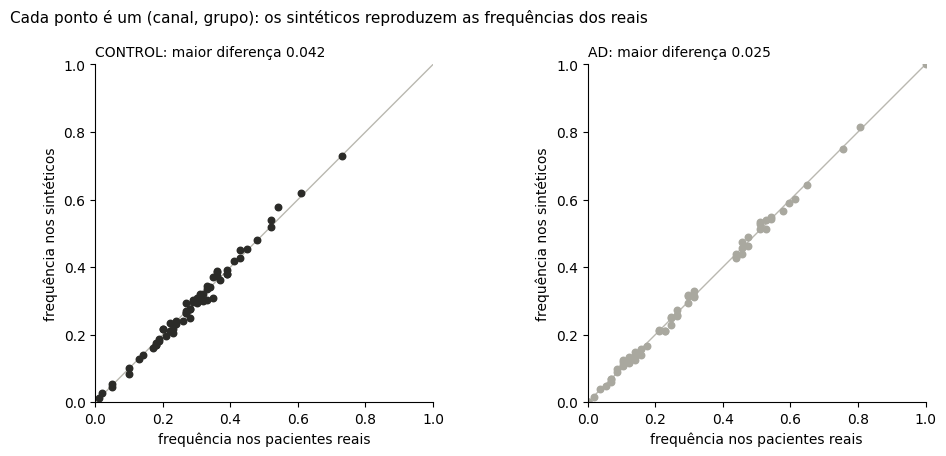

In [37]:
# Frequência de cada grupo do corte em cada canal: reais (x) contra sintéticos (y)
fig, eixos = plt.subplots(1, len(ESTADOS), figsize=(10, 4.6))
for ax, estado in zip(eixos, ESTADOS):
    real = dados_estado[estado]
    sint = sinteticos.loc[sinteticos.origem == estado, CANAIS]
    fr = np.array([(real[c] == v).mean() for c in CANAIS for v in range(K_POR_CANAL[c])])
    fs = np.array([(sint[c] == v).mean() for c in CANAIS for v in range(K_POR_CANAL[c])])
    ax.plot([0, 1], [0, 1], color='#b9b8b0', lw=1, zorder=1)
    ax.scatter(fr, fs, s=22, color=CORES[estado], zorder=2)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect('equal')
    ax.set_xlabel('frequência nos pacientes reais'); ax.set_ylabel('frequência nos sintéticos')
    ax.set_title(f'{estado}: maior diferença {np.abs(fr - fs).max():.3f}', loc='left', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Cada ponto é um (canal, grupo): os sintéticos reproduzem as frequências dos reais', x=0.02, ha='left', fontsize=11)
fig.tight_layout()
mostrar(fig, 'validacao')

## 6. Passo 6 — Classificação: CONTROL ou AD?

Cada indivíduo é avaliado pelos dois modelos, e o escore é a razão de verossimilhança em escala log:

$$\text{escore}(x) = \log P_{CONTROL}(x) - \log P_{AD}(x)$$

Escore > 0 → o modelo CONTROL explica melhor o indivíduo → classificado como **CONTROL**; escore < 0 → **AD**.
As probabilidades usam a suavização de Laplace (`prob_suavizada`), porque um indivíduo de um estado pode ter padrões que o outro estado nunca teve.

Três avaliações:

1. **Sintéticos** (2 × `N_SINTETICOS`): mede o quanto os padrões aprendidos de CONTROL e AD se distinguem.
   Os sintéticos vêm dos mesmos modelos que os classificam, então isto é separação entre modelos, não acurácia de diagnóstico.
2. **Pacientes reais:** os mesmos pacientes que construíram os modelos (sem validação cruzada nesta versão), então o resultado é otimista.
3. **Comparação:** o mesmo classificador com os canais tratados como independentes (cada canal é o seu próprio grupo).
   Se agrupar os canais pelo DAMICORE não melhorar o resultado, a estrutura aprendida no passo 3 não está ajudando.
   A referência mínima é chutar sempre CONTROL.

In [38]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score

def log_verossimilhanca(X, modelo):
    ll = np.zeros(len(X))
    for item in modelo.values():
        chaves = map(tuple, X[item['canais']].to_numpy().tolist())
        ll += np.log([(item['contagens'].get(c, 0) + ALFA) / (item['n'] + ALFA * item['possiveis']) for c in chaves])
    return ll

def escore(X, modelos):
    return log_verossimilhanca(X, modelos['CONTROL']) - log_verossimilhanca(X, modelos['AD'])

def classe(s):
    return np.where(s > 0, 'CONTROL', 'AD')

MODELO_INDEP = {e: montar_modelo(dados_estado[e], {i: [c] for i, c in enumerate(CANAIS)}) for e in ESTADOS}
reais = tabela[CANAIS]
y_reais = tabela.estado.values
y_sint = sinteticos.origem.values

def avaliar(conjunto, modelo, y, s):
    return dict(conjunto=conjunto, modelo=modelo, n=len(y), acuracia=accuracy_score(y, classe(s)),
                acuracia_balanceada=balanced_accuracy_score(y, classe(s)),
                AUC=roc_auc_score(y == 'CONTROL', s), empates=int((s == 0).sum()))

ESCORES = {
    ('sintéticos', 'DAMICORE'): escore(sinteticos[CANAIS], MODELO),
    ('sintéticos', 'canais independentes'): escore(sinteticos[CANAIS], MODELO_INDEP),
    ('reais', 'DAMICORE'): escore(reais, MODELO),
    ('reais', 'canais independentes'): escore(reais, MODELO_INDEP),
}
linhas = [avaliar(c, m, y_sint if c == 'sintéticos' else y_reais, s) for (c, m), s in ESCORES.items()]
linhas.append(dict(conjunto='reais', modelo='sempre CONTROL (referência)', n=len(y_reais),
                   acuracia=float(np.mean(y_reais == 'CONTROL')), acuracia_balanceada=0.5, AUC=0.5, empates=0))
METRICAS = pd.DataFrame(linhas).set_index(['conjunto', 'modelo'])

tabela_classif = tabela[['estado']].assign(escore=ESCORES['reais', 'DAMICORE'],
                                           classe_prevista=classe(ESCORES['reais', 'DAMICORE']))
tabela_classif.to_csv(SAIDA_K / 'classificacao_reais.csv')
sinteticos.assign(escore=ESCORES['sintéticos', 'DAMICORE'],
                  classe_prevista=classe(ESCORES['sintéticos', 'DAMICORE'])).to_csv(SAIDA_K / 'classificacao_sinteticos.csv')
METRICAS.style.format({'acuracia': '{:.3f}', 'acuracia_balanceada': '{:.3f}', 'AUC': '{:.3f}'})

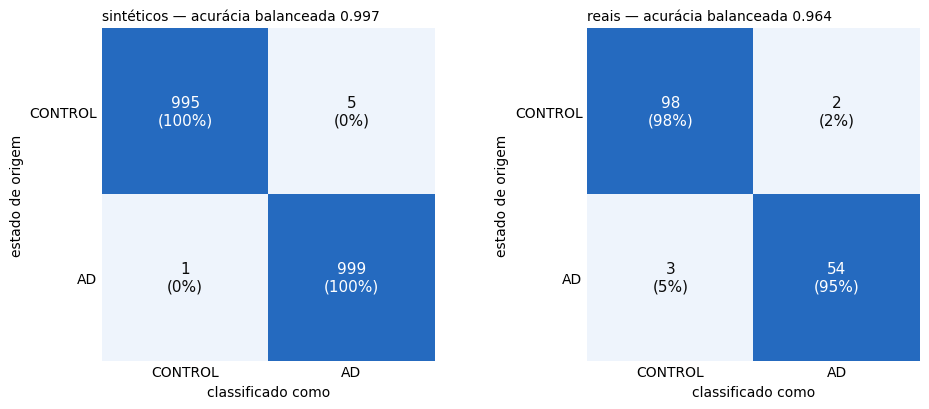

In [39]:
def matriz(y, s):
    m = pd.crosstab(pd.Series(y, name='estado real'), pd.Series(classe(s), name='classificado como'))
    return m.reindex(index=ESTADOS, columns=ESTADOS, fill_value=0)

MATRIZES = {'sintéticos': matriz(y_sint, ESCORES['sintéticos', 'DAMICORE']),
            'reais': matriz(y_reais, ESCORES['reais', 'DAMICORE'])}
fig, eixos = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (nome, m) in zip(eixos, MATRIZES.items()):
    frac = m.div(m.sum(axis=1), axis=0).values
    ax.imshow(frac, cmap=ListedColormap(['#eef4fc', '#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf']), vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{m.values[i, j]}\n({frac[i, j]:.0%})', ha='center', va='center', fontsize=11,
                    color='#ffffff' if frac[i, j] > 0.6 else '#0b0b0b')
    ax.set_xticks([0, 1], ESTADOS); ax.set_yticks([0, 1], ESTADOS)
    ax.set_xlabel('classificado como'); ax.set_ylabel('estado de origem')
    ax.set_title(f'{nome} — acurácia balanceada {METRICAS.loc[(nome, "DAMICORE"), "acuracia_balanceada"]:.3f}',
                 loc='left', fontsize=10)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
fig.tight_layout()
mostrar(fig, 'matrizes')

### 6.1 Distribuição dos escores

Em cima, os escores dos sintéticos de cada estado; embaixo, cada paciente real é um ponto.
Os dois controles `normal1` e `normal2` estão marcados: eles estão no mesmo formato de arquivo dos AD (`export`),
então, se caírem do lado AD, é sinal de que o formato pesa mais do que o estado.

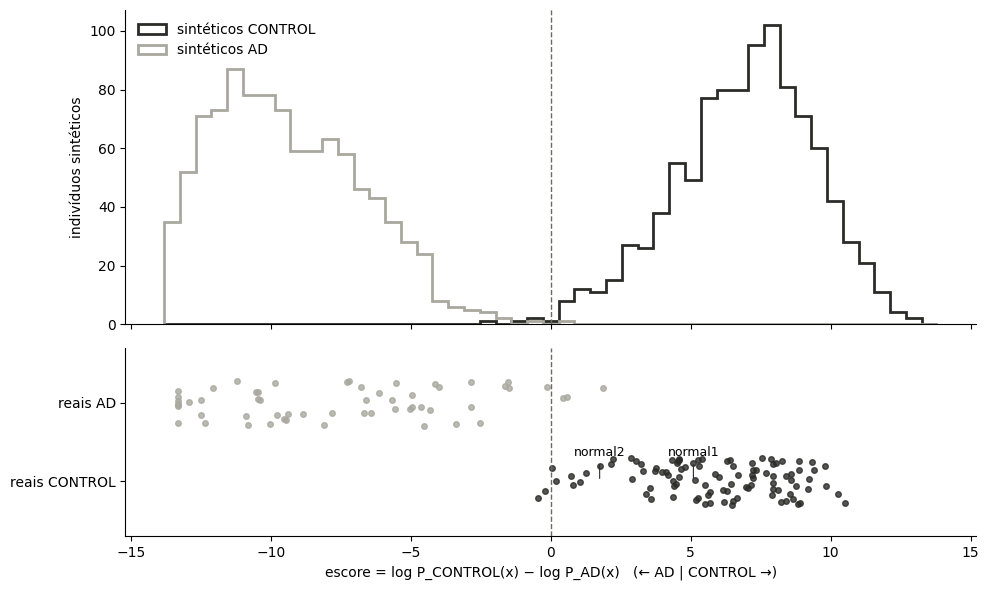

,estado,escore,classe_prevista
paciente,,,
normal1,CONTROL,5.094058,CONTROL
normal2,CONTROL,1.744733,CONTROL


In [40]:
s_sint, s_real = ESCORES['sintéticos', 'DAMICORE'], ESCORES['reais', 'DAMICORE']
lim = np.percentile(np.abs(np.concatenate([s_sint, s_real])), 99.5)
bins = np.linspace(-lim, lim, 50)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw=dict(height_ratios=[2, 1.2]))
for estado in ESTADOS:
    ax1.hist(s_sint[y_sint == estado], bins=bins, histtype='step', lw=2, color=CORES[estado], label=f'sintéticos {estado}')
ax1.axvline(0, color='#6b6a63', lw=1, ls='--')
ax1.set_ylabel('indivíduos sintéticos')
ax1.legend(frameon=False, loc='upper left')
ax1.spines[['top', 'right']].set_visible(False)

jitter = np.random.default_rng(0).uniform(-0.3, 0.3, len(s_real))
for k, estado in enumerate(ESTADOS):
    sel = y_reais == estado
    ax2.scatter(s_real[sel], k + jitter[sel], s=16, color=CORES[estado], alpha=0.8)
NORMAIS = tabela_classif.loc[[p for p in ['normal1', 'normal2'] if p in tabela_classif.index]]
for pid, r in NORMAIS.iterrows():
    ax2.annotate(pid, (r.escore, 0), xytext=(0, 18), textcoords='offset points', ha='center', fontsize=9,
                 arrowprops=dict(arrowstyle='-', color='#2b2b28', lw=0.8))
ax2.axvline(0, color='#6b6a63', lw=1, ls='--')
ax2.set_yticks(range(len(ESTADOS)), [f'reais {e}' for e in ESTADOS])
ax2.set_ylim(-0.7, len(ESTADOS) - 0.3)
ax2.set_xlabel('escore = log P_CONTROL(x) − log P_AD(x)   (← AD | CONTROL →)')
ax2.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
mostrar(fig, 'escores')
NORMAIS

## 7. Relatório

O relatório HTML reúne a configuração, o fluxo com os números desta execução, os resultados principais de cada passo,
a classificação e as ressalvas. Ele é um arquivo único (as figuras vão embutidas) e pode ser impresso em PDF pelo navegador.

Cada execução grava `relatorio_<modo>_<configuração>.html` e `metricas_<modo>_<configuração>.json`. O relatório lê todos os arquivos
de métricas e monta uma **tabela comparativa entre as configurações já executadas**. Para comparar, basta trocar `HARMONIZAR` (0.1)
ou os K no painel (2.4) e executar de novo. Quando o outro modo já foi executado com a mesma configuração (ou com K=2 em todos os canais),
o relatório traz também a comparação do viés de aparelho canal a canal.

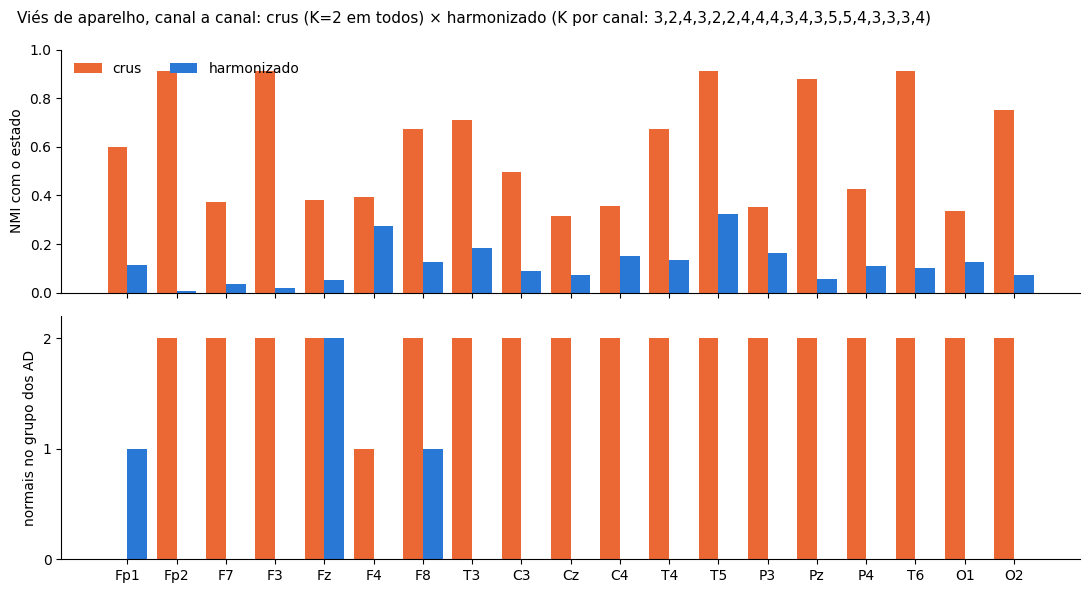

executado em  NMI estado (média) normais seguem formato  grupos CONTROL  grupos AD    ARI  ocupação média novos (C / AD)  \
modo        configuração                                                                                                                                                                       
harmonizado K=2 em todos                                        2026-11-19 15:45               0.074                3 de 38               6          6 -0.023           0.775     100% / 91%   
            K por canal: 3,2,4,3,2,2,4,4,4,3,4,3,5,5,4,3,3,3,4  2026-11-19 15:59               0.116                4 de 38               6          6  0.104           0.463     100% / 99%   
crus        K=2 em todos                                        2026-11-19 14:57               0.598               35 de 38               4          2 -0.089           0.595       55% / 0%   

                                                                ac. bal. sintéticos  ac. bal. reais  AUC reais  ac. bal. reais (indep.)  normal1 / normal2  
modo        configuração                                                                                                                                    
harmonizado K=2 em todos                                                      0.990           0.886      0.955                    0.814  CONTROL / CONTROL  
            K por canal: 3,2,4,3,2,2,4,4,4,3,4,3,5,5,4,3,3,3,4                0.997           0.964      0.997                    0.882  CONTROL / CONTROL  
crus        K=2 em todos                                                      0.999           0.990      0.998                    0.990            AD / AD

In [41]:
DIR_RELATORIOS = SAIDA / 'relatorios'
DIR_RELATORIOS.mkdir(exist_ok=True)
agora = datetime.now()

def m(conjunto, modelo, campo):
    return float(METRICAS.loc[(conjunto, modelo), campo])

metricas = dict(
    modo=MODO, config=CONFIG, k_por_canal=K_POR_CANAL, k_do_painel=K_DO_PAINEL,
    data=agora.isoformat(timespec='seconds'), n_sinteticos=N_SINTETICOS, alfa=ALFA, semente=SEMENTE,
    nmi_estado=corte.NMI_estado.to_dict(), nmi_formato=corte.NMI_formato.to_dict(),
    normais_seguem_formato=corte.normais_seguem_formato.astype(int).to_dict(),
    canais_repetidos={e: list(REPETIDOS[e].values()) for e in ESTADOS},
    pacientes={e: int(N_ESTADO[e]) for e in ESTADOS}, retirados=retirados.paciente.tolist(),
    k_automatico=K_AUTO.astype(int).to_dict(), avisos_corte=AVISOS_CORTE,
    grupos_canais={e: {str(g): cs for g, cs in GRUPOS[e].items()} for e in ESTADOS},
    modularidade=MODULARIDADE, ari_estados=ARI_ESTADOS,
    ocupacao_media=float(RESUMO_TABELAS.ocupacao.mean()), n_tabelas=len(RESUMO_TABELAS),
    novos={e: float(NOVIDADE.loc[e, 'novos']) for e in ESTADOS},
    metricas=[dict(conjunto=c, modelo=mo, **{k: float(v) for k, v in r.items()}) for (c, mo), r in METRICAS.iterrows()],
    normais={pid: dict(escore=float(r.escore), classe=r.classe_prevista) for pid, r in NORMAIS.iterrows()},
)
(DIR_RELATORIOS / f'metricas_{MODO}_{CONFIG}.json').write_text(json.dumps(metricas, indent=2, ensure_ascii=False), encoding='utf-8')

def descrever_k(kpc):
    v = sorted(set(kpc.values()))
    return f'K={v[0]} em todos' if len(v) == 1 else 'K por canal: ' + ','.join(str(kpc[c]) for c in CANAIS)

# Tabela comparativa: todas as configurações já executadas
EXECUCOES = {}
for f in DIR_RELATORIOS.glob('metricas_*.json'):
    d = json.loads(f.read_text(encoding='utf-8'))
    if 'config' in d:
        EXECUCOES[d['modo'], d['config']] = d
comparativo = []
for (modo, config), d in sorted(EXECUCOES.items(), key=lambda kv: (kv[0][0] != 'harmonizado', kv[1]['data'])):
    mm = {(x['conjunto'], x['modelo']): x for x in d['metricas']}
    comparativo.append({
        'modo': modo, 'configuração': descrever_k(d['k_por_canal']), 'executado em': d['data'].replace('T', ' ')[:16],
        'NMI estado (média)': round(np.mean(list(d['nmi_estado'].values())), 3),
        'normais seguem formato': f"{sum(d['normais_seguem_formato'].values())} de {2 * len(CANAIS)}",
        'grupos CONTROL': len(d['grupos_canais']['CONTROL']), 'grupos AD': len(d['grupos_canais']['AD']),
        'ARI': round(d['ari_estados'], 3), 'ocupação média': round(d['ocupacao_media'], 3),
        'novos (C / AD)': f"{d['novos']['CONTROL']:.0%} / {d['novos']['AD']:.0%}",
        'ac. bal. sintéticos': round(mm['sintéticos', 'DAMICORE']['acuracia_balanceada'], 3),
        'ac. bal. reais': round(mm['reais', 'DAMICORE']['acuracia_balanceada'], 3),
        'AUC reais': round(mm['reais', 'DAMICORE']['AUC'], 3),
        'ac. bal. reais (indep.)': round(mm['reais', 'canais independentes']['acuracia_balanceada'], 3),
        'normal1 / normal2': ' / '.join(d['normais'][p]['classe'] for p in ['normal1', 'normal2'] if p in d['normais']),
    })
COMPARATIVO = pd.DataFrame(comparativo).set_index(['modo', 'configuração'])

# Comparação canal a canal do viés de aparelho com o outro modo: mesma configuração, ou K=2 em todos os canais
OUTRO = 'crus' if MODO == 'harmonizado' else 'harmonizado'
CONFIG_OUTRO = CONFIG if (OUTRO, CONFIG) in EXECUCOES else ('K2' if (OUTRO, 'K2') in EXECUCOES else None)
if CONFIG_OUTRO:
    par = {MODO: EXECUCOES[MODO, CONFIG], OUTRO: EXECUCOES[OUTRO, CONFIG_OUTRO]}
    modos = ['crus', 'harmonizado']
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
    x = np.arange(len(CANAIS))
    for j, (modo, cor) in enumerate(zip(modos, ['#eb6834', '#2a78d6'])):
        d = par[modo]
        ax1.bar(x + (j - 0.5) * 0.4, [d['nmi_estado'][c] for c in CANAIS], 0.4, color=cor, label=modo)
        ax2.bar(x + (j - 0.5) * 0.4, [d['normais_seguem_formato'][c] for c in CANAIS], 0.4, color=cor, label=modo)
    ax1.set_ylabel('NMI com o estado'); ax1.set_ylim(0, 1); ax1.legend(frameon=False, ncol=2, loc='upper left')
    ax2.set_ylabel('normais no grupo dos AD'); ax2.set_ylim(0, 2.2); ax2.set_yticks([0, 1, 2])
    ax2.set_xticks(x, CANAIS)
    for a in (ax1, ax2):
        a.spines[['top', 'right']].set_visible(False)
    fig.suptitle(f"Viés de aparelho, canal a canal: crus ({descrever_k(par['crus']['k_por_canal'])}) × "
                 f"harmonizado ({descrever_k(par['harmonizado']['k_por_canal'])})", x=0.02, ha='left', fontsize=11)
    fig.tight_layout()
    mostrar(fig, 'vies_modos')
COMPARATIVO

In [42]:
def tab(df, fmt=None, indice=True):
    estilo = df.style.format(fmt or {}, precision=3).hide(axis='index') if not indice else df.style.format(fmt or {}, precision=3)
    return estilo.set_table_attributes('class="tabela"').to_html()

def fig_html(nome, legenda):
    if nome not in FIGURAS:
        return ''
    return f'<figure><img src="data:image/png;base64,{FIGURAS[nome]}" alt="{html.escape(legenda)}"><figcaption>{html.escape(legenda)}</figcaption></figure>'

esc = html.escape
nC, nA = int(N_ESTADO['CONTROL']), int(N_ESTADO['AD'])
bal_sint, bal_real = m('sintéticos', 'DAMICORE', 'acuracia_balanceada'), m('reais', 'DAMICORE', 'acuracia_balanceada')
auc_real, bal_indep = m('reais', 'DAMICORE', 'AUC'), m('reais', 'canais independentes', 'acuracia_balanceada')
novos_txt = ' | '.join(f"{e} {NOVIDADE.loc[e, 'novos']:.0%}" for e in ESTADOS)

MODO_TXT = (f'harmonizados ({FS_ALVO} Hz, {BANDA_HZ[0]:g}–{BANDA_HZ[1]:g} Hz, z-score, {N_NIVEIS} níveis)' if HARMONIZAR
            else 'crus (valores originais, sem processamento)')
FLUXO = [
    ('1. Objetos', f'{N_INVENTARIO} pacientes lidos', f'{len(retirados.paciente.unique())} retirados · CONTROL {nC} | AD {nA}<br>sinais {MODO_TXT} · 19 pastas de canal'),
    ('2. Discretização', (f'corte das árvores em K = {K_MAX_SEL}' if len(set(K_POR_CANAL.values())) == 1 else f'K por canal, de {min(K_POR_CANAL.values())} a {K_MAX_SEL}'), f'DAMICORE por canal (NCD → NJ)<br>k automático entre {K_AUTO.min()} e {K_AUTO.max()}'),
    ('3. Grupos de canais', f"CONTROL {len(GRUPOS['CONTROL'])} | AD {len(GRUPOS['AD'])} grupos", f'DAMICORE com canais como objetos<br>ARI entre estados {ARI_ESTADOS:.2f}'),
    ('4. Modelo', f'{len(RESUMO_TABELAS)} tabelas de probabilidade', f'P(x) = ∏ P_g(x_g)<br>ocupação média {RESUMO_TABELAS.ocupacao.mean():.0%}'),
    ('5. Sintéticos', f'{N_SINTETICOS} por estado', f'indivíduos novos: {novos_txt}'),
    ('6. Classificação', f'acurácia balanceada {bal_sint:.2f}', f'nos sintéticos<br>reais: {bal_real:.2f} (AUC {auc_real:.2f})'),
]
fluxo_html = '<div class="fluxo">' + '<div class="seta">→</div>'.join(
    f'<div class="caixa"><div class="passo">{t}</div><div class="destaque">{d}</div><div class="detalhe">{x}</div></div>'
    for t, d, x in FLUXO) + '</div>'

numeros = [(f'{bal_sint:.2f}', 'acurácia balanceada nos sintéticos', 'separação entre os modelos'),
           (f'{bal_real:.2f}', 'acurácia balanceada nos reais', f'AUC {auc_real:.2f} · otimista (sem validação)'),
           (f'{bal_indep:.2f}', 'reais, canais independentes', 'sem a estrutura do DAMICORE'),
           (f'{ARI_ESTADOS:.2f}', 'ARI dos grupos de canais', 'CONTROL × AD (0 = sem relação)')]
numeros_html = '<div class="numeros">' + ''.join(
    f'<div class="numero"><div class="valor">{v}</div><div class="rotulo">{r}</div><div class="nota">{n}</div></div>'
    for v, r, n in numeros) + '</div>'

grupos_df = pd.DataFrame([dict(estado=e, grupo=g, canais=', '.join(cs), n_canais=len(cs))
                          for e in ESTADOS for g, cs in GRUPOS[e].items()])
normais_txt = '; '.join(f'{pid}: escore {r.escore:+.2f} → {r.classe_prevista}' for pid, r in NORMAIS.iterrows()) or 'não estão no estudo'
avisos_txt = ('<li><b>Cortes com menos grupos que o K pedido:</b> ' + esc(', '.join(AVISOS_CORTE)) + '.</li>') if AVISOS_CORTE else ''
escolha_item = ('<li><b>K escolhidos no painel.</b> Os K de cada canal foram definidos olhando as árvores com a faixa do estado, '
                'ou seja, a discretização foi ajustada usando o diagnóstico. Sem validação cruzada, isso deixa a classificação dos reais mais otimista.</li>'
                if K_DO_PAINEL else '')
nmi_medio = corte.NMI_estado.mean()
seguem = int(corte.normais_seguem_formato.sum())
repetidos_txt = '; '.join(f"{e}: " + ' | '.join(', '.join(cs) for cs in REPETIDOS[e].values()) for e in ESTADOS if REPETIDOS[e])
VIES_TXT = (f'NMI médio entre a discretização e o estado: {nmi_medio:.2f}. Os dois controles no formato dos AD caíram no grupo dos AD '
            f'em {seguem} de {2 * len(CANAIS)} casos (canal × paciente).')
if MODO == 'crus':
    vies_item = (f'<li><b>Sinais crus e viés de aparelho.</b> Sem harmonização. Quase todos os controles são arquivos <code>fir</code> (inteiros, 128 Hz) '
                 f'e todos os AD são <code>export</code>, então formato e estado se confundem. {VIES_TXT} '
                 f'Na classificação, {esc(normais_txt)}. É este resultado que justifica harmonizar antes de aplicar o DAMICORE.</li>')
else:
    vies_item = (f'<li><b>Harmonização reduz, mas não elimina o viés de aparelho.</b> Reamostragem, banda comum e z-score igualam taxa, filtros e escala, '
                 f'mas os aparelhos continuam diferentes, e quase todos os controles vêm de um só. {VIES_TXT} '
                 f'Na classificação, {esc(normais_txt)}.</li>')
repetidos_item = (f'<li><b>Canais idênticos no passo 3</b> entraram no DAMICORE como um só objeto: {esc(repetidos_txt)}.</li>') if repetidos_txt else ''

RESSALVAS = f"""
<ul>
{vies_item}
<li><b>Sintéticos classificados pelos modelos que os geraram.</b> A acurácia nos sintéticos mede o quanto os padrões de CONTROL e AD se distinguem, não um diagnóstico.</li>
<li><b>Pacientes reais sem validação cruzada.</b> Os mesmos pacientes construíram os modelos e foram classificados: o resultado é otimista. A validação cruzada fica para o V4.</li>
<li><b>NCD com objetos pequenos no passo 3.</b> Cada canal vira uma sequência de {nA} (AD) ou {nC} (CONTROL) valores; com objetos desse tamanho o NCD é instável
e pequenos detalhes podem mudar os grupos de canais.</li>
<li><b>Rótulos dos grupos.</b> O número de um grupo do corte não tem o mesmo significado de um canal para outro (cada canal é uma árvore própria);
o modelo de probabilidade não depende desses rótulos.</li>
<li><b>MCI fora do estudo</b> nesta versão; a classificação em três estados é objetivo do V4.</li>
{escolha_item}
{repetidos_item}
{avisos_txt}
</ul>"""

CSS = """
:root{--fundo:#ffffff;--texto:#1f1f1c;--suave:#5f5e57;--linha:#e3e2dc;--painel:#f6f6f3;--destaque:#2a78d6}
*{box-sizing:border-box}
body{margin:0;background:var(--fundo);color:var(--texto);font:15px/1.55 system-ui,-apple-system,'Segoe UI',Roboto,sans-serif}
main{max-width:1080px;margin:0 auto;padding:32px 16px 64px}
h1{font-size:28px;margin:0 0 4px}
h2{font-size:20px;margin:40px 0 8px;padding-top:16px;border-top:1px solid var(--linha)}
p,li{max-width:80ch}
.sub{color:var(--suave);margin:0 0 20px}
.config{display:flex;flex-wrap:wrap;gap:8px;margin:12px 0 24px}
.config span{background:var(--painel);border:1px solid var(--linha);border-radius:999px;padding:3px 12px;font-size:13px}
.fluxo{display:flex;flex-wrap:wrap;align-items:stretch;gap:6px;margin:16px 0}
.caixa{flex:1 1 140px;background:var(--painel);border:1px solid var(--linha);border-radius:10px;padding:10px 12px}
.passo{font-size:12px;color:var(--suave);text-transform:uppercase;letter-spacing:.04em}
.destaque{font-weight:600;margin:4px 0}
.detalhe{font-size:13px;color:var(--suave)}
.seta{align-self:center;color:var(--suave);font-size:20px}
.numeros{display:grid;grid-template-columns:repeat(auto-fit,minmax(200px,1fr));gap:12px;margin:16px 0}
.numero{border:1px solid var(--linha);border-radius:10px;padding:12px 14px}
.valor{font-size:30px;font-weight:650;color:var(--destaque);font-variant-numeric:tabular-nums}
.rotulo{font-weight:600}
.nota{font-size:13px;color:var(--suave)}
.rolagem{overflow-x:auto}
table.tabela{border-collapse:collapse;font-size:13px;margin:8px 0 16px;font-variant-numeric:tabular-nums}
table.tabela th,table.tabela td{border-bottom:1px solid var(--linha);padding:4px 10px;text-align:left}
table.tabela thead th{background:var(--painel)}
figure{margin:16px 0}
figure img{max-width:100%;height:auto;border:1px solid var(--linha);border-radius:8px}
figcaption{font-size:13px;color:var(--suave);margin-top:4px}
code{background:var(--painel);padding:0 4px;border-radius:4px}
@media print{main{max-width:none;padding:0}h2{break-before:auto}figure,.caixa,.numero{break-inside:avoid}}
"""

relatorio = f"""<!doctype html>
<html lang="pt-BR"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>DAMICORE v3 — {MODO}, {CONFIG}</title><style>{CSS}</style></head>
<body><main>
<h1>DAMICORE v3 — EEG: Controle × Alzheimer <span style="color:var(--suave);font-weight:400">· {MODO}, {CONFIG}</span></h1>
<p class="sub">Ciclo de um Algoritmo de Estimação de Distribuição aplicado à identificação do estado a partir do EEG · gerado em {agora:%d/%m/%Y %H:%M}</p>
<div class="config"><span>sinais {esc(MODO_TXT)}</span><span>{esc(descrever_k(K_POR_CANAL))}</span><span>grupos de canais: automático</span>
<span>{N_SINTETICOS} sintéticos por estado</span><span>Laplace α = {ALFA}</span><span>semente {SEMENTE}</span><span>sem MCI · sem validação cruzada</span></div>

<h2>Fluxo desta execução</h2>
{fluxo_html}
{numeros_html}

<h2>1. Objetos</h2>
<p>{N_INVENTARIO} pacientes com 19 canais foram lidos. {len(retirados.paciente.unique())} foram retirados por terem canal plano
({esc(', '.join(f'{r.paciente} ({r.canal_plano})' for r in retirados.itertuples())) or 'nenhum'}).
Ficaram {nC} CONTROL e {nA} AD. Os sinais entram {esc(MODO_TXT)}: cada canal de cada paciente é um objeto de {N_AMOSTRAS} amostras
({BYTES_OBJETO} bytes), e cada canal tem uma pasta com todos os pacientes juntos.</p>
{fig_html('sinais', 'Canal P3 de um controle fir, de um controle export (normal1) e de um AD.')}

<h2>2. Discretização</h2>
<p>O DAMICORE rodou em cada um dos 19 canais com todos os pacientes juntos, sem usar o diagnóstico: NCD entre os pacientes, filograma por Neighbor Joining
e k automático pela modularidade (entre {K_AUTO.min()} e {K_AUTO.max()}). Cada filograma foi cortado no seu K ({esc(K_TXT)}{'; escolhidos no painel do notebook' if K_DO_PAINEL else ''}), e o grupo de cada paciente em cada canal é a sua discretização.</p>
<p><b>Viés de aparelho:</b> {esc(VIES_TXT)}</p>
<div class="rolagem">{tab(corte)}</div>
{fig_html('discretizacao', f'Tabela de discretização: {nC + nA} pacientes × 19 canais, cor = grupo do corte de cada canal.')}
{fig_html('mapa_k', 'NMI entre os grupos do corte e o estado, para cada canal e cada K possível.')}
{fig_html('arvores', 'Filogramas dos 19 canais com o corte aplicado: ramos cortados em vermelho e numerados na ordem do corte; faixas à direita = estado e grupo.')}

<h2>3. Grupos de canais</h2>
<p>A tabela de discretização foi separada por estado, e o DAMICORE rodou sobre cada uma com os canais como objetos e número de grupos automático.
Canais do mesmo grupo dividem os pacientes de modo parecido e são tratados como dependentes no modelo. O ARI entre as duas partições é {ARI_ESTADOS:.3f}
(modularidade: CONTROL {MODULARIDADE['CONTROL']:.3f}, AD {MODULARIDADE['AD']:.3f}).</p>
{tab(grupos_df, indice=False)}
{fig_html('escalpo', 'Grupos de canais de cada estado na posição dos eletrodos (sistema 10-20, nariz para cima).')}

<h2>4. Tabelas de probabilidade</h2>
<p>Para cada estado e grupo de canais, a tabela de probabilidade lista os padrões que aparecem nos pacientes e a sua frequência.
O modelo de cada estado é o produto dessas tabelas: P(x) = ∏ P<sub>g</sub>(x<sub>g</sub>). A ocupação é a fração dos padrões possíveis (produto dos K dos canais do grupo) que aparece.</p>
<div class="rolagem">{tab(RESUMO_TABELAS)}</div>

<h2>5. Indivíduos sintéticos</h2>
<p>Foram gerados {N_SINTETICOS} indivíduos por estado, sorteando um padrão de cada tabela de probabilidade. Como os grupos são sorteados de forma independente,
surgem combinações que nenhum paciente real tem.</p>
<div class="rolagem">{tab(NOVIDADE)}</div>
{fig_html('validacao', 'Frequência de cada grupo do corte em cada canal, pacientes reais × sintéticos.')}

<h2>6. Classificação</h2>
<p>Escore = log P<sub>CONTROL</sub>(x) − log P<sub>AD</sub>(x), com suavização de Laplace; escore &gt; 0 → CONTROL. A comparação com canais independentes
mostra o efeito da estrutura aprendida pelo DAMICORE; a referência mínima é chutar sempre CONTROL.</p>
<div class="rolagem">{tab(METRICAS)}</div>
{fig_html('matrizes', 'Matrizes de confusão do modelo DAMICORE: sintéticos e pacientes reais.')}
{fig_html('escores', 'Escores dos sintéticos (em cima) e dos pacientes reais (embaixo); normal1 e normal2 são controles no formato dos AD.')}

<h2>Ressalvas</h2>
{RESSALVAS}

<h2>Comparação entre configurações</h2>
<p>Cada linha é a execução mais recente de um modo e uma configuração de K. "Normais seguem formato" conta, somando os 19 canais, quantas vezes
<code>normal1</code> e <code>normal2</code> (controles no formato dos AD) caíram no grupo dos AD na discretização.</p>
<div class="rolagem">{tab(COMPARATIVO)}</div>
{fig_html('vies_modos', 'Em cima: NMI entre a discretização e o estado em cada canal. Embaixo: quantos dos dois controles export caíram no grupo dos AD. Laranja = crus, azul = harmonizado.')}
</main></body></html>"""

ARQUIVO_RELATORIO = DIR_RELATORIOS / f'relatorio_{MODO}_{CONFIG}.html'
ARQUIVO_RELATORIO.write_text(relatorio, encoding='utf-8')
print(f'Relatório: {ARQUIVO_RELATORIO} ({ARQUIVO_RELATORIO.stat().st_size / 1024:.0f} KB)')

Relatório: c:\DAMICORE\DAMICORE_v3\saida\relatorios\relatorio_harmonizado_Kcanal_10c752.html (1069 KB)
